<a href="https://colab.research.google.com/github/tiwausman/canadian-wildfire-big-data/blob/main/notebooks/Canadian_Wildfire_Analysis_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Geospatial Big Data Analysis of Wildfires in Canada**

# **Phase 1: Data Understanding and Validation**

This phase establishes whether the Canadian National Fire Database (NFDB) point dataset and its summary workbook are suitable for analysis. The code below uses Python, PySpark, Pandas, and GeoPandas to inspect the data, identify quality issues, validate date and coordinate fields, and document decisions before proceeding to exploratory analysis.
The files are named NFDB_point.csv and NFDB_point_stats.xlsx. Adjust the file paths to match your project folders.

**Step 1. Set up the environment**

Install the required packages in your active Python environment. PySpark also requires a compatible Java installation.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving NFDB_point_stats.xlsx to NFDB_point_stats.xlsx


In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    NumericType,
    StringType,
    DateType,
    TimestampType
)


DATA_DIR = Path("/content")
CSV_PATH = DATA_DIR / "NFDB_point.csv"
WORKBOOK_PATH = DATA_DIR / "NFDB_point_stats.xlsx"

# Initialize Apache Spark so PySpark can process and analyze the Canadian wildfire dataset.
# Create a Spark session
spark = (
    SparkSession.builder
    .appName("CanadianWildfireDataValidation")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("CSV exists:", CSV_PATH.exists())
print("Workbook exists:", WORKBOOK_PATH.exists())

Spark version: 4.0.4
CSV exists: True
Workbook exists: False


**Step 2. Inspect the summary workbook**

The summary workbook provides context for interpreting the CSV. Inspect its sheet names, dimensions, header rows, units, year coverage, thresholds, source notes, and provenance before calculating results.

**2.1 List all workbook sheets**

In [ ]:
excel_file = pd.ExcelFile(WORKBOOK_PATH)

print("Workbook sheets:")
for sheet in excel_file.sheet_names:
    print("-", sheet)

Workbook sheets:
- NFDB_Summary_Stats
- NFDB_Summary_Stats_By_Agency
- Park_Stats
- NFDB_Cause_Stats
- NFDB_Cause_Stats_By_Agency
- BNDFFC_Statistiques_sommaires
- BNDFFC_Stats_sommaires_par_jur
- Parcs_Stats
- BNDFFC_stats_par_cause
- Stats_par_cause_et_par_agence
- CNFDB_SumStats_Src_Data
- Sources


**2.2 Inspect the first rows of each sheet**

Do not assume that every sheet uses the same header row. Some sheets may contain titles, explanatory notes, or blank rows before the table header.

In [ ]:
for sheet in excel_file.sheet_names:
    print(f"\n{'=' * 70}")
    print("SHEET:", sheet)

    preview = pd.read_excel(
        WORKBOOK_PATH,
        sheet_name=sheet,
        header=None,
        nrows=12
    )

    print(preview.to_string(index=False, header=False))


SHEET: NFDB_Summary_Stats
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        CNFDB Summary statistics - Number of fires and area burned by year                 NaN             NaN            NaN                             NaN               NaN                      NaN
                                                                                    

**Step 3. Load the CSV into PySpark**

Read the CSV with headers and automatic schema inference. Initially, keep the source data unchanged so validation does not accidentally discard records.

In [ ]:
df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("mode", "PERMISSIVE")
    .csv(str(CSV_PATH))
)

print("Column names:")
print(df.columns)

print("\nSchema:")
df.printSchema()

print("\nFirst five records:")
df.show(5, truncate=False)

Column names:
['FID', 'nfdbfireid', 'src_agency', 'nat_park', 'fire_id', 'firename', 'latitude', 'longitude', 'year', 'month', 'day', 'rep_date', 'attk_date', 'out_date', 'size_ha', 'fire_type', 'response', 'protzone', 'prescribed', 'more_info', 'cfs_note1', 'cfs_note2', 'acq_date', 'cause', 'cause2', 'geometry']

Schema:
root
 |-- FID: string (nullable = true)
 |-- nfdbfireid: string (nullable = true)
 |-- src_agency: string (nullable = true)
 |-- nat_park: string (nullable = true)
 |-- fire_id: string (nullable = true)
 |-- firename: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day: integer (nullable = true)
 |-- rep_date: date (nullable = true)
 |-- attk_date: date (nullable = true)
 |-- out_date: date (nullable = true)
 |-- size_ha: double (nullable = true)
 |-- fire_type: string (nullable = true)
 |-- response: string (nullable = true)
 |-- p

**3.1 Check row count and column count**

In [ ]:
row_count = df.count()
column_count = len(df.columns)

print("Number of records:", row_count)
print("Number of columns:", column_count)

Number of records: 10000
Number of columns: 26


**3.2 Profile numeric and categorical columns**

In [ ]:
# Summary statistics for numeric fields
numeric_columns = [
    field.name
    for field in df.schema.fields
    if isinstance(field.dataType, NumericType)
]

if numeric_columns:
    df.select(*numeric_columns).describe().show(
        truncate=False
    )

# Count distinct values in selected categorical columns
categorical_candidates = [
    "agency", "cause", "fire_type", "fire_name",
    "prescribed", "nat_park"
]

for column in categorical_candidates:
    if column in df.columns:
        print(f"\nValue counts for {column}:")
        (
            df.groupBy(column)
            .count()
            .orderBy(F.desc("count"))
            .show(50, truncate=False)
        )

+-------+-----------------+-------------------+-----------------+------------------+-----------------+------------------+
|summary|latitude         |longitude          |year             |month             |day              |size_ha           |
+-------+-----------------+-------------------+-----------------+------------------+-----------------+------------------+
|count  |10000            |10000              |10000            |10000             |10000            |10000             |
|mean   |56.7505335100002 |-107.42309809000001|2013.4452        |6.2821            |14.8864          |8543.152469390026 |
|stddev |5.036201345545614|18.409198046041823 |8.714137397303004|1.8181447013413161|9.733486996801897|31485.027704753247|
|min    |0.0              |-141.0             |1970             |0                 |0                |200.0             |
|max    |69.6025          |93.4628            |2025             |12                |31               |885388.2142       |
+-------+---------------

Some columns may be inferred as strings even when they contain numbers. Inspect the schema before deciding whether to convert them.

**Step 4. Profile missing values**

Missing values may be represented as nulls, empty strings, or strings such as "NA". Profile each representation before normalizing it.

In [ ]:
# Count nulls and empty strings in every column
missing_expressions = []

for column in df.columns:
    value = F.trim(F.col(column).cast("string"))

    missing_expressions.append(
        F.sum(
            F.when(
                F.col(column).isNull() |
                (value == ""),
                1
            ).otherwise(0)
        ).alias(column)
    )

missing_counts = df.select(*missing_expressions).first().asDict()

missing_report = pd.DataFrame({
    "column": list(missing_counts.keys()),
    "missing_count": list(missing_counts.values())
})

missing_report["missing_percent"] = (
    missing_report["missing_count"] / row_count * 100
)

missing_report = missing_report.sort_values(
    "missing_percent",
    ascending=False
)

print(missing_report.to_string(index=False))

    column  missing_count  missing_percent
 attk_date           9994            99.94
prescribed           9912            99.12
 cfs_note2           9875            98.75
  nat_park           9592            95.92
 cfs_note1           9358            93.58
  firename           7690            76.90
 more_info           7346            73.46
  protzone           7285            72.85
  response           6332            63.32
 fire_type           5412            54.12
  out_date           2933            29.33
  rep_date            544             5.44
  acq_date            274             2.74
  latitude              0             0.00
   fire_id              0             0.00
src_agency              0             0.00
       FID              0             0.00
nfdbfireid              0             0.00
     month              0             0.00
      year              0             0.00
 longitude              0             0.00
       day              0             0.00
   size_ha 

To inspect common text placeholders such as "NA" or "Unknown":

In [ ]:
placeholders = ["NA", "N/A", "NULL", "NONE", "UNKNOWN"]

for column in df.columns:
    if isinstance(df.schema[column].dataType, StringType):
        value = F.upper(F.trim(F.col(column)))

        count_expr = F.sum(
            F.when(value.isin(placeholders), 1).otherwise(0)
        ).alias("placeholder_count")

        count = df.select(count_expr).first()[0]

        if count and count > 0:
            print(f"{column}: {count} placeholder values")

firename: 1 placeholder values
response: 4 placeholder values
protzone: 6 placeholder values


**Important:** Do not automatically replace every placeholder or remove every row with missing values. For example, an unknown fire cause may still be useful for annual fire counts and burned-area analysis.

**Step 5. Validate the year range**

Identify the year field in your actual CSV. The following code uses fire_year; if the dataset uses a different name, replace it with the correct column.

In [ ]:
YEAR_COL = "year"

if YEAR_COL in df.columns:
    df = df.withColumn(
        YEAR_COL,
        F.col(YEAR_COL).cast("int")
    )

    df.select(
        F.min(YEAR_COL).alias("earliest_year"),
        F.max(YEAR_COL).alias("latest_year"),
        F.count(F.col(YEAR_COL)).alias("non_null_years"),
        F.countDistinct(YEAR_COL).alias("distinct_years")
    ).show()

    # Review year frequencies
    (
        df.groupBy(YEAR_COL)
        .count()
        .orderBy(YEAR_COL)
        .show(100, truncate=False)
    )
else:
    print(
        f"Column '{YEAR_COL}' not found. "
        "Inspect df.columns and set YEAR_COL to the actual year field."
    )

+-------------+-----------+--------------+--------------+
|earliest_year|latest_year|non_null_years|distinct_years|
+-------------+-----------+--------------+--------------+
|         1970|       2025|         10000|            36|
+-------------+-----------+--------------+--------------+

+----+-----+
|year|count|
+----+-----+
|1970|4    |
|1972|24   |
|1973|40   |
|1974|4    |
|1975|10   |
|1995|5    |
|1996|1    |
|1997|1    |
|1998|8    |
|1999|242  |
|2000|182  |
|2001|175  |
|2002|322  |
|2003|414  |
|2004|432  |
|2005|303  |
|2006|416  |
|2007|256  |
|2008|203  |
|2009|233  |
|2010|386  |
|2011|233  |
|2012|420  |
|2013|374  |
|2014|341  |
|2015|546  |
|2016|204  |
|2017|468  |
|2018|429  |
|2019|192  |
|2020|80   |
|2021|596  |
|2022|425  |
|2023|965  |
|2024|535  |
|2025|531  |
+----+-----+



**Step 6. Validate the fire-size distribution**

The size_ha field represents fire size in hectares in the project dataset. Confirm its units using the workbook and official documentation.

In [ ]:
SIZE_COL = "size_ha"

if SIZE_COL in df.columns:
    df = df.withColumn(
        SIZE_COL,
        F.col(SIZE_COL).cast("double")
    )

    df.select(
        F.count(SIZE_COL).alias("non_null_sizes"),
        F.min(SIZE_COL).alias("minimum_ha"),
        F.expr(f"percentile_approx({SIZE_COL}, 0.25)").alias("q1_ha"),
        F.expr(f"percentile_approx({SIZE_COL}, 0.50)").alias("median_ha"),
        F.expr(f"percentile_approx({SIZE_COL}, 0.75)").alias("q3_ha"),
        F.expr(f"percentile_approx({SIZE_COL}, 0.95)").alias("p95_ha"),
        F.max(SIZE_COL).alias("maximum_ha"),
        F.avg(SIZE_COL).alias("mean_ha")
    ).show(truncate=False)

    # Flag missing, zero, or negative values
    df.select(
        F.sum(
            F.when(F.col(SIZE_COL).isNull(), 1).otherwise(0)
        ).alias("missing_size"),
        F.sum(
            F.when(F.col(SIZE_COL) == 0, 1).otherwise(0)
        ).alias("zero_size"),
        F.sum(
            F.when(F.col(SIZE_COL) < 0, 1).otherwise(0)
        ).alias("negative_size")
    ).show()

+--------------+----------+-----+---------+-------+-------+-----------+-----------------+
|non_null_sizes|minimum_ha|q1_ha|median_ha|q3_ha  |p95_ha |maximum_ha |mean_ha          |
+--------------+----------+-----+---------+-------+-------+-----------+-----------------+
|10000         |200.0     |493.0|1417.0   |5358.02|33000.0|885388.2142|8543.152469390026|
+--------------+----------+-----+---------+-------+-------+-----------+-----------------+

+------------+---------+-------------+
|missing_size|zero_size|negative_size|
+------------+---------+-------------+
|           0|        0|            0|
+------------+---------+-------------+



**6.1 Inspect the 200-hectare threshold**

In [ ]:
large_fire_summary = df.agg(
    F.count("*").alias("total_records"),

    F.sum(
        F.when(F.col(SIZE_COL) > 200, 1).otherwise(0)
    ).alias("fires_over_200_ha"),

    F.sum(
        F.when(F.col(SIZE_COL) <= 200, 1).otherwise(0)
    ).alias("fires_200_ha_or_less"),

    F.sum(
        F.when(F.col(SIZE_COL) > 200, F.col(SIZE_COL))
        .otherwise(0)
    ).alias("area_from_fires_over_200_ha"),

    F.sum(SIZE_COL).alias("total_recorded_area")
)

large_fire_summary.show(truncate=False)

+-------------+-----------------+--------------------+---------------------------+-------------------+
|total_records|fires_over_200_ha|fires_200_ha_or_less|area_from_fires_over_200_ha|total_recorded_area|
+-------------+-----------------+--------------------+---------------------------+-------------------+
|10000        |9865             |135                 |8.540452469390027E7        |8.543152469390027E7|
+-------------+-----------------+--------------------+---------------------------+-------------------+



**6.2 Visualize the size distribution**

Fire sizes are often highly right-skewed. A logarithmic axis can make the distribution easier to inspect.

In [ ]:
import matplotlib.pyplot as plt

sizes = (
    df.select(SIZE_COL)
    .where(
        F.col(SIZE_COL).isNotNull() &
        (F.col(SIZE_COL) > 0)
    )
    .toPandas()[SIZE_COL]
)

plt.figure(figsize=(10, 5))
plt.hist(np.log10(sizes), bins=40)
plt.xlabel("log10(Fire size in hectares)")
plt.ylabel("Number of records")
plt.title("Distribution of Canadian Wildfire Sizes")
plt.tight_layout()
plt.show()

**Step 7. Validate month and day values**

The dataset may contain month and day values of zero. These are not valid calendar components, so treat them as unknown or invalid rather than constructing dates from them.

In [ ]:
for column in ["month", "day"]:
    if column in df.columns:
        df = df.withColumn(
            column,
            F.col(column).cast("int")
        )

        print(f"\nValue frequencies for {column}:")
        (
            df.groupBy(column)
            .count()
            .orderBy(column)
            .show(40, truncate=False)
        )

Create explicit flags and normalized components without deleting the original values.

In [ ]:
if "month" in df.columns:
    df = df.withColumn(
        "month_invalid_or_unknown",
        F.col("month").isNull() |
        (F.col("month") < 1) |
        (F.col("month") > 12)
    )

if "day" in df.columns:
    df = df.withColumn(
        "day_invalid_or_unknown",
        F.col("day").isNull() |
        (F.col("day") < 1) |
        (F.col("day") > 31)
    )

if "month" in df.columns:
    df = df.withColumn(
        "month_clean",
        F.when(
            F.col("month").between(1, 12),
            F.col("month")
        )
    )

if "day" in df.columns:
    df = df.withColumn(
        "day_clean",
        F.when(
            F.col("day").between(1, 31),
            F.col("day")
        )
    )

The range checks above identify invalid components, but they do not validate complete calendar dates. For example, day 31 is not valid in every month. If I construct full dates later, validate the combination of year, month, and day using a strict date parser. Retain unknown dates as missing rather than imputing arbitrary dates.

**Step 8. Investigate repeated fire identifiers**

Repeated identifiers do not automatically mean that records are duplicates. First determine whether the dataset's identifier is intended to be unique, and inspect the records involved.

In [ ]:
ID_COL = "nfdbfireid"

if ID_COL in df.columns:
    duplicate_ids = (
        df.groupBy(ID_COL)
        .count()
        .filter(
            (F.col(ID_COL).isNotNull()) &
            (F.col("count") > 1)
        )
        .orderBy(F.desc("count"))
    )

    print("Repeated non-null identifiers:")
    duplicate_ids.show(100, truncate=False)

    # Inspect all rows for repeated identifiers
    repeated_id_values = (
        duplicate_ids.select(ID_COL)
    )

    df.join(
        repeated_id_values,
        on=ID_COL,
        how="inner"
    ).orderBy(ID_COL).show(100, truncate=False)

Check exact row duplicates separately.

In [ ]:
print(
    "Exact duplicate rows:",
    df.count() - df.dropDuplicates().count()
)

Exact duplicate rows: 0


Decision rule: Do not remove repeated IDs until you have checked the source documentation and compared relevant attributes such as year, agency, fire name, date, size, and location. An exact repeated row may be a duplicate record; a repeated ID with differing attributes may indicate a data-quality issue or an identifier whose scope is not globally unique.

These appear to be duplicate records in this extract. However, confirm this by comparing all substantive fields and checking the source documentation before removing either pair.
The differing FID values suggest separate feature records in the source file, but do not establish why the records were duplicated.
*** **compare the two records while excluding FID, which appears to be a feature-level identifier:**

In [ ]:
from pyspark.sql import functions as F

duplicate_ids = [
    "MB-2021-MB2021EA136",
    "MB-2021-MB2021NO031"
]

review_df = df.filter(
    F.col("nfdbfireid").isin(duplicate_ids)
)

# Compare all fields except FID
comparison_columns = [
    c for c in df.columns
    if c not in ["FID"]
]

(
    review_df
    .select(*comparison_columns)
    .orderBy("nfdbfireid")
    .show(truncate=False)
)

+-------------------+----------+--------+-----------+--------+--------+---------+----+-----+---+----------+---------+--------+---------+---------+--------+--------+----------+-------------+--------------------------------------------------+---------+----------+-----+------+---------------------------------------------+------------------------+----------------------+-----------+---------+
|nfdbfireid         |src_agency|nat_park|fire_id    |firename|latitude|longitude|year|month|day|rep_date  |attk_date|out_date|size_ha  |fire_type|response|protzone|prescribed|more_info    |cfs_note1                                         |cfs_note2|acq_date  |cause|cause2|geometry                                     |month_invalid_or_unknown|day_invalid_or_unknown|month_clean|day_clean|
+-------------------+----------+--------+-----------+--------+--------+---------+----+-----+---+----------+---------+--------+---------+---------+--------+--------+----------+-------------+-----------------------------

output confirms that both repeated nfdbfireid values are exact duplicates in all the displayed substantive fields. The only differences identified in the earlier output were their FID values.

**Step 9. Investigate repeated geometry values**

A geometry value may repeat because multiple records share a location, because coordinates are rounded, or because the source contains duplicate records. Repeated geometry alone is not sufficient evidence for deletion.

In [ ]:
GEOMETRY_COL = "geometry"

if GEOMETRY_COL in df.columns:
    repeated_geometry = (
        df.groupBy(GEOMETRY_COL)
        .count()
        .filter(
            F.col(GEOMETRY_COL).isNotNull() &
            (F.col("count") > 1)
        )
        .orderBy(F.desc("count"))
    )

    print("Repeated geometry values:")
    repeated_geometry.show(50, truncate=False)

Repeated geometry values:
+----------------------------------------------+-----+
|geometry                                      |count|
+----------------------------------------------+-----+
|POINT (11205750.009000003 3787032.700099997)  |4    |
|POINT (-1044521.3069999963 2010477.7774999999)|2    |
|POINT (-559390.7321999967 948609.2584999986)  |2    |
|POINT (-762338.5763000026 1087061.8566000015) |2    |
|POINT (-139497.83079999685 573723.0733000003) |2    |
|POINT (-710833.0362000018 1313548.6708999984) |2    |
|POINT (-1497313.4243 722929.3850999996)       |2    |
|POINT (-1049353.5895999968 1718497.2210000008)|2    |
|POINT (-627981.2018999979 948982.1191000007)  |2    |
|POINT (-509209.3599999994 1115336.7142999992) |2    |
|POINT (-625442.3589999974 1362002.9299000017) |2    |
|POINT (-1473647.0078000017 758019.2109000012) |2    |
|POINT (-643868.8590999991 938575.7182999998)  |2    |
|POINT (-92461.93940000236 284032.8344999999)  |2    |
+--------------------------------------

To compare records with repeated geometry, display the available identifying fields.

In [ ]:
inspection_columns = [
    c for c in [
        "nfdbfireid", "fire_year", "agency",
        "fire_name", "size_ha", "cause",
        "latitude", "longitude", "geometry"
    ]
    if c in df.columns
]

if GEOMETRY_COL in df.columns:
    repeated_geometry_values = (
        repeated_geometry.select(GEOMETRY_COL)
    )

    (
        df.join(
            repeated_geometry_values,
            on=GEOMETRY_COL,
            how="inner"
        )
        .select(*inspection_columns)
        .orderBy(GEOMETRY_COL)
        .show(100, truncate=False)
    )

+--------------------+---------+-----+--------+---------+----------------------------------------------+
|nfdbfireid          |size_ha  |cause|latitude|longitude|geometry                                      |
+--------------------+---------+-----+--------+---------+----------------------------------------------+
|NT-2012-VQ037-12    |1056.7   |N    |65.6167 |-118.9333|POINT (-1044521.3069999963 2010477.7774999999)|
|NT-2012-VQ043-12    |472.38   |N    |65.6167 |-118.9333|POINT (-1044521.3069999963 2010477.7774999999)|
|NT-2012-ZF036-12    |200.0    |N    |63.0722 |-116.8357|POINT (-1049353.5895999968 1718497.2210000008)|
|NT-2012-ZF040-12    |1151.0   |N    |63.0722 |-116.8357|POINT (-1049353.5895999968 1718497.2210000008)|
|MB-2021-MB2021NO031 |3851.9059|N    |54.1817 |-97.1736 |POINT (-139497.83079999685 573723.0733000003) |
|MB-2021-MB2021NO031 |3851.9059|N    |54.1817 |-97.1736 |POINT (-139497.83079999685 573723.0733000003) |
|PC-JA-2003-JA-4     |1375.0   |H    |53.4267 |-118.0  

**Step 10. Validate latitude and longitude**

Latitude and longitude must be numeric and within their conventional geographic bounds:
- Latitude: −90 to +90 degrees.
- Longitude: −180 to +180 degrees.
These bounds are necessary but do not guarantee that a coordinate is geographically correct for Canada.

In [ ]:
LAT_COL = "latitude"
LON_COL = "longitude"

if LAT_COL in df.columns and LON_COL in df.columns:
    df = (
        df
        .withColumn(LAT_COL, F.col(LAT_COL).cast("double"))
        .withColumn(LON_COL, F.col(LON_COL).cast("double"))
    )

    df.select(
        F.min(LAT_COL).alias("min_latitude"),
        F.max(LAT_COL).alias("max_latitude"),
        F.min(LON_COL).alias("min_longitude"),
        F.max(LON_COL).alias("max_longitude")
    ).show()

    coordinate_checks = df.select(
        F.sum(
            F.when(
                F.col(LAT_COL).isNull() |
                F.col(LON_COL).isNull(),
                1
            ).otherwise(0)
        ).alias("missing_coordinates"),

        F.sum(
            F.when(
                ~F.col(LAT_COL).between(-90, 90) |
                ~F.col(LON_COL).between(-180, 180),
                1
            ).otherwise(0)
        ).alias("outside_global_bounds"),

        F.sum(
            F.when(
                (F.col(LAT_COL) == 0) |
                (F.col(LON_COL) == 0),
                1
            ).otherwise(0)
        ).alias("contains_zero_coordinate")
    )

    coordinate_checks.show()

+------------+------------+-------------+-------------+
|min_latitude|max_latitude|min_longitude|max_longitude|
+------------+------------+-------------+-------------+
|         0.0|     69.6025|       -141.0|      93.4628|
+------------+------------+-------------+-------------+

+-------------------+---------------------+------------------------+
|missing_coordinates|outside_global_bounds|contains_zero_coordinate|
+-------------------+---------------------+------------------------+
|                  0|                    0|                       6|
+-------------------+---------------------+------------------------+



Inspect questionable records rather than dropping them immediately.

In [ ]:
if LAT_COL in df.columns and LON_COL in df.columns:
    (
        df.filter(
            F.col(LAT_COL).isNull() |
            F.col(LON_COL).isNull() |
            ~F.col(LAT_COL).between(-90, 90) |
            ~F.col(LON_COL).between(-180, 180) |
            (F.col(LAT_COL) == 0) |
            (F.col(LON_COL) == 0)
        )
        .select(*inspection_columns)
        .show(100, truncate=False)
    )

+-------------------+-------+-----+--------+---------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|nfdbfireid         |size_ha|cause|latitude|longitude|geometry                                                                                                                                                                                                                                                             

A zero coordinate is a review flag, not proof that the value is wrong. For the previously inspected extract, a latitude of zero paired with a longitude around 93.46 warrants investigation because it is inconsistent with the expected geographic location of a Canadian wildfire.

**Step 11. Confirm the coordinate reference system (CRS)**

Before mapping or calculating distances and areas, determine how the geometry field is encoded and which CRS it uses. Do not assume that the geometry and latitude/longitude fields use the same coordinate system.

**11.1 Inspect geometry values**

In [ ]:
if GEOMETRY_COL in df.columns:
    (
        df.select(GEOMETRY_COL)
        .where(F.col(GEOMETRY_COL).isNotNull())
        .show(10, truncate=False)
    )

+---------------------------------------------+
|geometry                                     |
+---------------------------------------------+
|POINT (-583760.1931999996 1219426.4188)      |
|POINT (-162846.27489999682 276333.6774000004)|
|POINT (-289663.7457000017 270255.9754000008) |
|POINT (-42986.519500002265 377641.3328000009)|
|POINT (-33268.51479999721 377939.83900000155)|
|POINT (-19336.42279999703 298004.54190000147)|
|POINT (-315866.6274000034 87285.9739000015)  |
|POINT (-101853.46140000224 89407.8935999982) |
|POINT (-31683.108499996364 280537.1169999987)|
|POINT (-1059398.4019000009 749342.9730000012)|
+---------------------------------------------+
only showing top 10 rows


Look for values such as POINT (longitude latitude), WKB/hexadecimal strings, or another representation. The correct parsing method depends on the actual format.

**11.2 Inspect geometry using GeoPandas**

If the CSV contains WKT geometry and the source documentation confirms the CRS, you can parse a sample as follows. Replace SOURCE_CRS with the verified CRS identifier; do not choose one merely because it makes the map look correct.

In [ ]:
import geopandas as gpd

SOURCE_CRS = "EPSG:4326"  # Example only: use only if verified

sample_pd = (
    df.select(
        *[
            c for c in [
                "nfdbfireid", "fire_year",
                "latitude", "longitude", "geometry"
            ]
            if c in df.columns
        ]
    )
    .limit(1000)
    .toPandas()
)

if GEOMETRY_COL in sample_pd.columns:
    sample_pd["geometry"] = gpd.GeoSeries.from_wkt(
        sample_pd["geometry"],
        crs=SOURCE_CRS,
        on_invalid="warn"
    )

    gdf = gpd.GeoDataFrame(
        sample_pd,
        geometry="geometry",
        crs=SOURCE_CRS
    )

    print("CRS:", gdf.crs)
    print("Geometry types:")
    print(gdf.geom_type.value_counts(dropna=False))

    print("Geometry bounds:", gdf.total_bounds)
    print("Invalid geometries:", (~gdf.geometry.is_valid).sum())

CRS: EPSG:4326
Geometry types:
Point    1000
Name: count, dtype: int64
Geometry bounds: [-2093791.3743   -90613.7561  2964179.676   2653388.5087]
Invalid geometries: 0


**11.3 Compare geometry coordinates with latitude and longitude**

For point geometries in a verified geographic CRS, compare their coordinate values with the separate latitude and longitude columns.

In [ ]:
if (
    "latitude" in gdf.columns
    and "longitude" in gdf.columns
    and gdf.crs is not None
    and gdf.crs.is_geographic
):
    gdf["geometry_longitude"] = gdf.geometry.x
    gdf["geometry_latitude"] = gdf.geometry.y

    gdf["longitude_difference"] = (
        gdf["longitude"] - gdf["geometry_longitude"]
    )

    gdf["latitude_difference"] = (
        gdf["latitude"] - gdf["geometry_latitude"]
    )

    print(
        gdf[
            [
                "latitude", "longitude",
                "geometry_latitude", "geometry_longitude",
                "latitude_difference", "longitude_difference"
            ]
        ].head(20)
    )

    latitude  longitude  geometry_latitude  geometry_longitude  \
0    59.6850  -105.7080       1.219426e+06       -5.837602e+05   
1    51.4682   -97.3649       2.763337e+05       -1.628463e+05   
2    51.3539   -99.1966       2.702560e+05       -2.896637e+05   
3    52.4138   -95.6393       3.776413e+05       -4.298652e+04   
4    52.4173   -95.4948       3.779398e+05       -3.326851e+04   
5    51.6919   -95.2823       2.980045e+05       -1.933642e+04   
6    49.6876   -99.3923       8.728597e+04       -3.158666e+05   
7    49.7949   -96.4190       8.940789e+04       -1.018535e+05   
8    51.5328   -95.4608       2.805371e+05       -3.168311e+04   
9    54.5185  -111.8510       7.493430e+05       -1.059398e+06   
10   64.0636  -134.0461       2.193374e+06       -1.734126e+06   
11   64.1646  -134.3345       2.210156e+06       -1.738938e+06   
12   63.7850  -134.4354       2.179528e+06       -1.766649e+06   
13   64.8965  -134.4358       2.277310e+06       -1.696865e+06   
14   64.18

If the geometry is projected, first transform it to a verified geographic CRS:

In [ ]:
# Only after confirming the source CRS
gdf_geographic = gdf.to_crs("EPSG:4326")

**Step 12. Validate agency and fire-cause codes**

Inspect code frequencies before assigning meanings. Confirm the definitions against the NFDB codebook or source documentation.

In [ ]:
for column in ["agency", "cause", "fire_type"]:
    if column in df.columns:
        print(f"\nDistinct codes for {column}:")

        (
            df.groupBy(column)
            .count()
            .orderBy(F.desc("count"))
            .show(100, truncate=False)
        )


Distinct codes for cause:
+-----+-----+
|cause|count|
+-----+-----+
|N    |8336 |
|H    |997  |
|U    |667  |
+-----+-----+


Distinct codes for fire_type:
+----------------+-----+
|fire_type       |count|
+----------------+-----+
|NULL            |5412 |
|Wildfire        |1686 |
|Fire            |1447 |
|IFR             |788  |
|Crown           |237  |
|Surface         |225  |
|Ground          |48   |
|OFR             |30   |
|Mutual Aid      |21   |
|PB              |20   |
|Type 5          |19   |
|Prescribed Burn |15   |
|Type 3          |8    |
|Type 4          |7    |
|Forest          |7    |
|Req For Assist  |6    |
|1               |5    |
|99              |3    |
|5               |3    |
|Type 1          |3    |
|4               |3    |
|0               |2    |
|Type 2          |2    |
|3               |1    |
|Request For Ass*|1    |
|Grass           |1    |
+----------------+-----+



In [ ]:
if "cause" in df.columns:
    cause_audit = (
        df.groupBy("cause")
        .agg(
            F.count("*").alias("record_count"),
            F.sum("size_ha").alias("total_size_ha"),
            F.avg("size_ha").alias("mean_size_ha")
        )
        .orderBy(F.desc("record_count"))
    )

    cause_audit.show(truncate=False)

**Step 13. Generate a consolidated validation report**

This final step creates a small machine-readable report that I can retain as evidence of your data-understanding process.

In [ ]:
from datetime import datetime, timezone

report = {
    "validation_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "csv_path": str(CSV_PATH),
    "record_count": df.count(),
    "column_count": len(df.columns),
    "columns": ", ".join(df.columns)
}

if YEAR_COL in df.columns:
    year_stats = df.agg(
        F.min(YEAR_COL).alias("min_year"),
        F.max(YEAR_COL).alias("max_year")
    ).first()

    report["min_year"] = year_stats["min_year"]
    report["max_year"] = year_stats["max_year"]

if SIZE_COL in df.columns:
    size_stats = df.agg(
        F.min(SIZE_COL).alias("min_size_ha"),
        F.max(SIZE_COL).alias("max_size_ha"),
        F.avg(SIZE_COL).alias("mean_size_ha")
    ).first()

    report["min_size_ha"] = size_stats["min_size_ha"]
    report["max_size_ha"] = size_stats["max_size_ha"]
    report["mean_size_ha"] = size_stats["mean_size_ha"]

report_df = pd.DataFrame([report])

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

report_df.to_csv(
    OUTPUT_DIR / "phase1_validation_summary.csv",
    index=False
)

missing_report.to_csv(
    OUTPUT_DIR / "phase1_missing_values.csv",
    index=False
)

print(report_df.to_string(index=False))
print("\nValidation reports saved in:", OUTPUT_DIR.resolve())

        validation_timestamp_utc                csv_path  record_count  column_count                                                                                                                                                                                                                                                                                                                          columns  min_year  max_year  min_size_ha  max_size_ha  mean_size_ha
2026-10-15T16:04:04.829943+00:00 /content/NFDB_point.csv         10000            30 FID, nfdbfireid, src_agency, nat_park, fire_id, firename, latitude, longitude, year, month, day, rep_date, attk_date, out_date, size_ha, fire_type, response, protzone, prescribed, more_info, cfs_note1, cfs_note2, acq_date, cause, cause2, geometry, month_invalid_or_unknown, day_invalid_or_unknown, month_clean, day_clean      1970      2025        200.0  885388.2142   8543.152469

Validation reports saved in: /content/outputs


# **Phase 2: Cleaning and Feature Preparation**

The following PySpark code continues from Phase 1. It assumes your Spark session is named spark and your original DataFrame is df. It creates a separate cleaned DataFrame, preserves the original data, and records cleaning decisions.

**Step 1: Import libraries and preserve the original dataset**

In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.types import StringType
from pyspark.sql.functions import col, when, trim, upper

In [ ]:
from pyspark.sql import functions as F

# Reload the original CSV with its original columns
df_phase1 = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(CSV_PATH))
)

print("Original CSV columns:", len(df_phase1.columns))
print("Current DataFrame columns:", len(df.columns))
print("Columns in original CSV:", df_phase1.columns)
print("Additional columns:", set(df.columns) - set(df_phase1.columns))

Original CSV columns: 26
Current DataFrame columns: 30
Columns in original CSV: ['FID', 'nfdbfireid', 'src_agency', 'nat_park', 'fire_id', 'firename', 'latitude', 'longitude', 'year', 'month', 'day', 'rep_date', 'attk_date', 'out_date', 'size_ha', 'fire_type', 'response', 'protzone', 'prescribed', 'more_info', 'cfs_note1', 'cfs_note2', 'acq_date', 'cause', 'cause2', 'geometry']
Additional columns: {'month_clean', 'month_invalid_or_unknown', 'day_clean', 'day_invalid_or_unknown'}


Explanation: Keeping the original dataset allows to compare records before and after cleaning and reproduce decisions.

**Step 2: Standardize null and placeholder values**

Standardize blank strings and common placeholder values to NULL in textual fields. Do not replace meaningful categorical codes such as N, H, U, or PB without checking the NFDB data dictionary.

In [ ]:
# Columns containing textual information
string_columns = [
    field.name
    for field in df_phase1.schema.fields
    if isinstance(field.dataType, StringType)
]

# Values treated as placeholders (case-insensitive)
placeholders = ["", "NULL", "N/A", "NA", "UNKNOWN", "NONE"]

df_clean = df_phase1

for column_name in string_columns:
    cleaned_value = trim(col(column_name))

    df_clean = df_clean.withColumn(
        column_name,
        when(
            cleaned_value.isNull()
            | upper(cleaned_value).isin(placeholders),
            None
        ).otherwise(cleaned_value)
    )

print("Rows after placeholder standardization:", df_clean.count())

Rows after placeholder standardization: 10000


**Explanation:** This standardizes common textual placeholders while preserving the original number of records. The string "0" is deliberately retained because it may have a field-specific meaning.

**Step 3: Clean categorical fields**

Inspect the codes before recoding them.

In [ ]:
categorical_columns = [
    "cause", "cause2", "src_agency",
    "fire_type", "response", "prescribed", "protzone"
]

for column_name in categorical_columns:
    if column_name in df_clean.columns:
        print(f"\nValues in {column_name}:")
        (
            df_clean.groupBy(column_name)
                    .count()
                    .orderBy(F.desc("count"))
                    .show(50, truncate=False)
        )


Values in cause:
+-----+-----+
|cause|count|
+-----+-----+
|N    |8336 |
|H    |997  |
|U    |667  |
+-----+-----+


Values in cause2:
+------+-----+
|cause2|count|
+------+-----+
|N     |8354 |
|H     |912  |
|U     |680  |
|H-PB  |54   |
+------+-----+


Values in src_agency:
+----------+-----+
|src_agency|count|
+----------+-----+
|SK        |1689 |
|NT        |1653 |
|BC        |1447 |
|MB        |1332 |
|YT        |899  |
|QC        |879  |
|ON        |838  |
|AB        |708  |
|PC        |408  |
|NL        |123  |
|NS        |14   |
|NB        |10   |
+----------+-----+


Values in fire_type:
+----------------+-----+
|fire_type       |count|
+----------------+-----+
|NULL            |5412 |
|Wildfire        |1686 |
|Fire            |1447 |
|IFR             |788  |
|Crown           |237  |
|Surface         |225  |
|Ground          |48   |
|OFR             |30   |
|Mutual Aid      |21   |
|PB              |20   |
|Type 5          |19   |
|Prescribed Burn |15   |
|Type 3          |

**Explanation**

This identifies inconsistent labels and uncommon codes. Earlier results showed that fire_type contains both descriptive values and coded values, while cause contains N, H, and U.

Verify the codes against the official NFDB documentation before mapping them to descriptive labels. Until verified, preserve the original categorical codes.

**Step 4: Prepare valid date components**

Month and day values of zero are not valid calendar components. Retain the original fields and create separate cleaned fields.

In [ ]:
df_clean = (
    df_clean
    .withColumn(
        "month_clean",
        when(col("month").between(1, 12), col("month"))
    )
    .withColumn(
        "day_clean",
        when(col("day").between(1, 31), col("day"))
    )
)

# Flag incomplete or invalid date components
df_clean = (
    df_clean
    .withColumn(
        "month_invalid_or_unknown",
        col("month_clean").isNull()
    )
    .withColumn(
        "day_invalid_or_unknown",
        col("day_clean").isNull()
    )
)

# Season derived only from valid months
df_clean = df_clean.withColumn(
    "season",
    when(col("month_clean").isin(12, 1, 2), "Winter")
    .when(col("month_clean").isin(3, 4, 5), "Spring")
    .when(col("month_clean").isin(6, 7, 8), "Summer")
    .when(col("month_clean").isin(9, 10, 11), "Autumn")
)

df_clean.select(
    "year", "month", "day",
    "month_clean", "day_clean", "season"
).show(10, truncate=False)

**Explanation:**
Annual analysis can use year because it is complete in the extract. Month- and season-based analyses should use only valid month values. The code does not construct a full date from month and day alone, because day values such as February 31 would still be invalid.

**Step 5: Flag questionable geographic coordinates**

For this extract, use the approximate geographic bounds of Canada as a screening rule, not as proof that a coordinate is correct. Zero coordinates and suspicious longitude values should be investigated separately.

In [ ]:
df_clean = (
    df_clean
    .withColumn(
        "coordinate_suspect",
        col("latitude").isNull()
        | col("longitude").isNull()
        | (col("latitude") == 0)
        | (col("longitude") == 0)
        | (~col("latitude").between(41, 84))
        | (~col("longitude").between(-141, -52))
    )
)

print("Coordinate screening results:")
df_clean.groupBy("coordinate_suspect").count().show()

# Keep questionable records available for investigation
df_coordinate_issues = df_clean.filter(col("coordinate_suspect"))

# Separate subset for analyses requiring screened coordinates
df_spatial = df_clean.filter(~col("coordinate_suspect"))

print("All cleaned records:", df_clean.count())
print("Records flagged for coordinate review:", df_coordinate_issues.count())
print("Records passing coordinate screening:", df_spatial.count())

Coordinate screening results:
+------------------+-----+
|coordinate_suspect|count|
+------------------+-----+
|              true|   10|
|             false| 9990|
+------------------+-----+

All cleaned records: 10000
Records flagged for coordinate review: 10
Records passing coordinate screening: 9990


**Explanation: T**his flags coordinates that fall outside broad Canadian bounds or contain zero values. It does not silently replace or delete them. Important to confirm the appropriate geographic bounds and source CRS before using df_spatial for mapping or spatial calculations.

**Step 6: Investigate duplicate identifiers**

Do not automatically remove records simply because they share a location. First inspect repeated identifiers and compare substantive attributes.

In [ ]:
# Find repeated fire identifiers
duplicate_ids = (
    df_clean
    .filter(col("nfdbfireid").isNotNull())
    .groupBy("nfdbfireid")
    .count()
    .filter(col("count") > 1)
)

duplicate_ids.show(truncate=False)

# Inspect all records associated with repeated identifiers
repeated_id_records = df_clean.join(
    duplicate_ids.select("nfdbfireid"),
    on="nfdbfireid",
    how="inner"
)

repeated_id_records.orderBy("nfdbfireid").show(
    100, truncate=False
)

**Explanation:** earlier output identified two repeated identifiers whose substantive attributes matched. Keep them flagged until their duplicate status has been confirmed against the source. Retain records with different fire identifiers even if their geometry is identical, unless further evidence establishes duplication.

**Step 7: Document the CSV and workbook coverage**

CSV contains 10,000 records, while the workbook contains annual, agency, cause, and park summaries. These summaries may cover a wider dataset, different periods, or different inclusion criteria.

**Start** by recording the CSV coverage:

In [ ]:
csv_coverage = df_clean.agg(
    F.count("*").alias("record_count"),
    F.min("year").alias("min_year"),
    F.max("year").alias("max_year"),
    F.countDistinct("src_agency").alias("agency_count"),
    F.min("size_ha").alias("minimum_size_ha"),
    F.max("size_ha").alias("maximum_size_ha")
)

csv_coverage.show(truncate=False)

Next, record the workbook's coverage manually after inspecting its notes and summary tables:

In [ ]:
# Fill these values only after checking the workbook.
workbook_coverage = {
    "workbook_name": "NFDB_point_stats.xlsx",
    "coverage_start_year": 1970,
    "coverage_end_year": 2025,
    "threshold_definition": 200.0,
    "geographic_coverage": "Canada",
    "source_notes_reviewed": False
}

print(workbook_coverage)

{'workbook_name': 'NFDB_point_stats.xlsx', 'coverage_start_year': 1970, 'coverage_end_year': 2025, 'threshold_definition': 200.0, 'geographic_coverage': 'Canada', 'source_notes_reviewed': False}


**Step 8: Create a cleaning log**

In [ ]:
cleaning_log = [
    ("Text placeholders", "Standardized blank and common placeholder strings to NULL"),
    ("Categorical codes", "Preserved original codes pending data dictionary verification"),
    ("Dates", "Created clean month/day fields; invalid components retained as NULL"),
    ("Season", "Derived only from valid month values"),
    ("Coordinates", "Flagged zero and out-of-screening-range coordinates"),
    ("Duplicates", "Flagged repeated identifiers for investigation; no automatic deletion"),
    ("Coverage", "Recorded CSV coverage and identified workbook comparability checks")
]

cleaning_log_df = spark.createDataFrame(
    cleaning_log,
    ["cleaning_area", "decision"]
)

cleaning_log_df.show(truncate=False)

+-----------------+---------------------------------------------------------------------+
|cleaning_area    |decision                                                             |
+-----------------+---------------------------------------------------------------------+
|Text placeholders|Standardized blank and common placeholder strings to NULL            |
|Categorical codes|Preserved original codes pending data dictionary verification        |
|Dates            |Created clean month/day fields; invalid components retained as NULL  |
|Season           |Derived only from valid month values                                 |
|Coordinates      |Flagged zero and out-of-screening-range coordinates                  |
|Duplicates       |Flagged repeated identifiers for investigation; no automatic deletion|
|Coverage         |Recorded CSV coverage and identified workbook comparability checks   |
+-----------------+---------------------------------------------------------------------+



**Step 9: Validate the cleaned dataset**

In [ ]:
print("Original rows:", df_phase1.count())
print("Cleaned rows:", df_clean.count())

print("Missing values in key analytical fields:")

df_clean.select(
    F.sum(col("year").isNull().cast("int")).alias("missing_year"),
    F.sum(col("size_ha").isNull().cast("int")).alias("missing_size_ha"),
    F.sum(col("cause").isNull().cast("int")).alias("missing_cause"),
    F.sum(col("latitude").isNull().cast("int")).alias("missing_latitude"),
    F.sum(col("longitude").isNull().cast("int")).alias("missing_longitude")
).show()

Original rows: 10000
Cleaned rows: 10000
Missing values in key analytical fields:
+------------+---------------+-------------+----------------+-----------------+
|missing_year|missing_size_ha|missing_cause|missing_latitude|missing_longitude|
+------------+---------------+-------------+----------------+-----------------+
|           0|              0|            0|               0|                0|
+------------+---------------+-------------+----------------+-----------------+



**Important:** This phase prepares the data; it does not yet establish that the coordinate reference system is correct or that the 10,000-row extract represents all Canadian wildfire records. Those points must be resolved or documented before drawing national-level conclusions.

In [ ]:
from pyspark.sql import functions as F

df_phase2 = df_clean

print("Phase 2 rows:", df_phase2.count())
print("Phase 2 columns:", len(df_phase2.columns))

Phase 2 rows: 10000
Phase 2 columns: 27


In [ ]:
from pyspark.sql import functions as F

# Check coordinate ranges
df_phase2.select(
    F.min("latitude").alias("min_latitude"),
    F.max("latitude").alias("max_latitude"),
    F.min("longitude").alias("min_longitude"),
    F.max("longitude").alias("max_longitude")
).show()

# Check potentially unknown or invalid month/day values
df_phase2.groupBy("month").count().orderBy("month").show()
df_phase2.groupBy("day").count().orderBy("day").show()

+------------+------------+-------------+-------------+
|min_latitude|max_latitude|min_longitude|max_longitude|
+------------+------------+-------------+-------------+
|         0.0|     69.6025|       -141.0|      93.4628|
+------------+------------+-------------+-------------+

+-----+-----+
|month|count|
+-----+-----+
|    0|  541|
|    1|    6|
|    2|    9|
|    3|   24|
|    4|  172|
|    5|  942|
|    6| 2741|
|    7| 3981|
|    8| 1323|
|    9|  198|
|   10|   49|
|   11|   10|
|   12|    4|
+-----+-----+

+---+-----+
|day|count|
+---+-----+
|  0|  544|
|  1|  495|
|  2|  330|
|  3|  306|
|  4|  300|
|  5|  281|
|  6|  303|
|  7|  360|
|  8|  319|
|  9|  257|
| 10|  310|
| 11|  299|
| 12|  354|
| 13|  312|
| 14|  261|
| 15|  260|
| 16|  237|
| 17|  282|
| 18|  288|
| 19|  219|
+---+-----+
only showing top 20 rows


In [ ]:
from pyspark.sql import functions as F

# Flag suspicious geographic coordinates
df_phase2 = (
    df_phase2
    .withColumn(
        "coordinate_issue",
        (F.col("latitude") == 0) |
        (F.col("longitude") == 0) |
        (F.col("latitude") < 41) |
        (F.col("latitude") > 84) |
        (F.col("longitude") < -141) |
        (F.col("longitude") > -52)
    )
    .withColumn(
        "month_unknown",
        F.col("month") == 0
    )
    .withColumn(
        "day_unknown",
        F.col("day") == 0
    )
)

# Count records requiring investigation
df_phase2.select(
    F.sum(F.col("coordinate_issue").cast("int"))
        .alias("coordinate_issue_records"),
    F.sum(F.col("month_unknown").cast("int"))
        .alias("unknown_month_records"),
    F.sum(F.col("day_unknown").cast("int"))
        .alias("unknown_day_records")
).show()

# Inspect suspicious coordinate records
df_phase2.filter(
    F.col("coordinate_issue")
).select(
    "nfdbfireid", "src_agency", "year",
    "latitude", "longitude", "geometry"
).show(50, truncate=False)

+------------------------+---------------------+-------------------+
|coordinate_issue_records|unknown_month_records|unknown_day_records|
+------------------------+---------------------+-------------------+
|                      10|                  541|                544|
+------------------------+---------------------+-------------------+

+-------------------+----------+----+--------+---------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
!pip -q install pymupdf requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 61.8 MB/s eta 0:00:00


In [ ]:
import requests
import fitz
import re

metadata_url = (
    "https://scifv.scf.rncan.gc.ca/downloads/"
    "nfdb/fire_pnt/current_version/"
    "NFDB_point_shapefile_metadata.pdf"
)

response = requests.get(metadata_url, timeout=60)
response.raise_for_status()

with open("/content/NFDB_point_shapefile_metadata.pdf", "wb") as f:
    f.write(response.content)

pdf = fitz.open("/content/NFDB_point_shapefile_metadata.pdf")
metadata_text = "\n".join(page.get_text() for page in pdf)

print("PDF pages:", len(pdf))
print("PDF downloaded and text extracted successfully.")

PDF pages: 1
PDF downloaded and text extracted successfully.


In [ ]:
keywords = [
    "Spatial Reference",
    "NAD_1983_Canada_Atlas_Lambert",
    "3978",
    "LATITUDE",
    "LONGITUDE",
    "Latitude",
    "Longitude",
    "DESCRIPTION SOURCE",
    "Agency",
    "zero",
    "0,0",
]

for keyword in keywords:
    matches = list(
        re.finditer(re.escape(keyword), metadata_text, re.IGNORECASE)
    )

    print(f"\n{'=' * 60}\n{keyword}: {len(matches)} match(es)")

    for match in matches[:3]:
        start = max(0, match.start() - 250)
        end = min(len(metadata_text), match.end() + 500)
        print(metadata_text[start:end].replace("\n", " "))

In [ ]:
import requests
import zipfile
import os

shp_url = (
    "https://cwfis.cfs.nrcan.gc.ca/downloads/"
    "nfdb/fire_pnt/current_version/NFDB_point_shp.zip"
)

zip_path = "/content/NFDB_point_shp.zip"
extract_dir = "/content/NFDB_point_shp"

r = requests.get(shp_url, timeout=180)
r.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(r.content)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extracted to:", extract_dir)

In [ ]:
import glob

prj_files = glob.glob(
    "/content/NFDB_point_shp/**/*.prj",
    recursive=True
)

print("Projection files found:", len(prj_files))

for prj_file in prj_files:
    print("\nFile:", prj_file)
    with open(prj_file, "r", encoding="utf-8") as f:
        print(f.read())

In [ ]:
df_phase2.filter(
    F.col("src_agency").isin("PC", "NL")
).groupBy("src_agency").agg(
    F.count("*").alias("records"),
    F.sum(
        (
            (F.col("latitude") == 0) |
            (F.col("longitude") == 0)
        ).cast("int")
    ).alias("records_with_zero_coordinate"),
    F.sum(
        (
            (F.col("longitude") < -141) |
            (F.col("longitude") > -52) |
            (F.col("latitude") < 41) |
            (F.col("latitude") > 84)
        ).cast("int")
    ).alias("records_outside_screening_bounds")
).show(truncate=False)

In [ ]:
!pip -q install geopandas pyogrio

In [ ]:
import geopandas as gpd
import glob

shp_files = glob.glob(
    "/content/NFDB_point_shp/**/*.shp",
    recursive=True
)

print("Shapefiles found:", len(shp_files))

for shp_file in shp_files:
    gdf = gpd.read_file(shp_file)

    print("\nFile:", shp_file)
    print("CRS:", gdf.crs)
    print("CRS authority:", gdf.crs.to_authority() if gdf.crs else None)
    print("Geometry type:", gdf.geom_type.value_counts().to_dict())
    print("Bounds:", gdf.total_bounds)

    if gdf.crs:
        print("Axis information:", gdf.crs.axis_info)

Shapefiles found: 0


In [ ]:
import numpy as np
import pandas as pd

# Calculate bounds for each geometry
bounds = gdf.geometry.bounds.copy()
bounds.columns = ["minx", "miny", "maxx", "maxy"]

# Find records responsible for each dataset-wide extreme
extreme_indices = {
    "minimum X": bounds["minx"].idxmin(),
    "minimum Y": bounds["miny"].idxmin(),
    "maximum X": bounds["maxx"].idxmax(),
    "maximum Y": bounds["maxy"].idxmax(),
}

print("DATASET-WIDE EXTREME COORDINATES")
for label, idx in extreme_indices.items():
    print(f"\n{label}: row index {idx}")
    print("Bounds:", bounds.loc[idx].to_dict())
    print(gdf.loc[[idx]].drop(columns="geometry").to_string(index=False))
    print("Geometry:", gdf.geometry.loc[idx])

# Flag extremely large or non-finite coordinates
x = gdf.geometry.x
y = gdf.geometry.y

sentinel_candidates = (
    ~np.isfinite(x) |
    ~np.isfinite(y) |
    (np.abs(x) > 1e100) |
    (np.abs(y) > 1e100)
)

suspect = gdf.loc[sentinel_candidates].copy()

print("\nSENTINEL / EXTREME COORDINATE CANDIDATES")
print("Number of records:", len(suspect))

if len(suspect):
    print(
        suspect.drop(columns="geometry")
        .to_string(index=False)
    )
    print("\nGeometry values:")
    print(suspect.geometry.to_string())

DATASET-WIDE EXTREME COORDINATES

minimum X: row index 593
Bounds: {'minx': -2093791.3742999993, 'miny': 513162.48800000176, 'maxx': -2093791.3742999993, 'maxy': 513162.48800000176}
         nfdbfireid  latitude  longitude  geometry_longitude  geometry_latitude  longitude_difference  latitude_difference
BC-2025-2025-V71498   49.1252  -124.7763       -2.093791e+06         513162.488           2093666.598         -513113.3628
Geometry: POINT (-2093791.3742999993 513162.48800000176)

minimum Y: row index 532
Bounds: {'minx': 281812.7380999997, 'miny': -90613.75609999895, 'maxx': 281812.7380999997, 'maxy': -90613.75609999895}
  nfdbfireid  latitude  longitude  geometry_longitude  geometry_latitude  longitude_difference  latitude_difference
ON-2000-FOR1   48.1115   -91.2266         281812.7381        -90613.7561          -281903.9647           90661.8676
Geometry: POINT (281812.7380999997 -90613.75609999895)

maximum X: row index 595
Bounds: {'minx': 2964179.675999999, 'miny': 847250.336100

In [ ]:
float64_min = np.finfo(np.float64).min

print("Minimum finite float64:", float64_min)

print(
    "Coordinates equal to float64 minimum:",
    ((x == float64_min) | (y == float64_min)).sum()
)

print(
    "Coordinates below -1e300:",
    ((x < -1e300) | (y < -1e300)).sum()
)

print(
    "Coordinates with absolute value above 1e100:",
    ((np.abs(x) > 1e100) | (np.abs(y) > 1e100)).sum()
)

In [ ]:
# Identify the fire-ID field in the shapefile
id_candidates = [
    c for c in gdf.columns
    if c.lower() in ["nfdbfireid", "nfdb_fire_id", "fire_id"]
]

print("Potential ID fields:", id_candidates)

if id_candidates:
    id_col = id_candidates[0]

    suspect_ids = (
        suspect[id_col].dropna().astype(str).unique().tolist()
        if len(suspect) else []
    )

    print("Suspicious fire IDs:", suspect_ids)

    if suspect_ids:
        csv_matches = df_phase2.filter(
            df_phase2["nfdbfireid"].isin(suspect_ids)
        )

        print("Matching CSV records:")
        csv_matches.select(
            "nfdbfireid", "src_agency", "year",
            "latitude", "longitude", "geometry"
        ).show(100, truncate=False)
else:
    print("Inspect gdf.columns and identify the correct fire-ID field.")

Potential ID fields: ['nfdbfireid']
Suspicious fire IDs: []


# **Phase 2 — Final Data-Quality Validation and Cleaning**

## 2.1 Final Spatial Data-Quality Flags

The spatial quality assessment distinguishes between attribute-coordinate
problems and geometry problems.

Three separate conditions are evaluated:

1. Zero latitude/longitude coordinates.
2. Implausible latitude/longitude values.
3. Sentinel values in the geometry field.

Records are retained in the dataset and flagged rather than deleted.

In [ ]:
from pyspark.sql import functions as F

# Make sure we are working with the Phase 2 dataframe
df_phase2 = df_phase2

# ---------------------------------------------------------
# 1. Zero latitude/longitude
# ---------------------------------------------------------
df_phase2 = df_phase2.withColumn(
    "zero_coordinate_issue",
    (
        (F.col("latitude") == 0) &
        (F.col("longitude") == 0)
    )
)

# ---------------------------------------------------------
# 2. Implausible latitude/longitude
# ---------------------------------------------------------
# Reasonable screening bounds for Canadian wildfire analysis:
# Latitude: 41 to 84
# Longitude: -141 to -52
#
# These are screening rules, not official NFDB validity rules.

df_phase2 = df_phase2.withColumn(
    "implausible_coordinate_issue",
    (
        (F.col("latitude") < 41) |
        (F.col("latitude") > 84) |
        (F.col("longitude") < -141) |
        (F.col("longitude") > -52)
    )
)

# ---------------------------------------------------------
# 3. Sentinel geometry
# ---------------------------------------------------------
# The official shapefile contains coordinates equal to the
# minimum float64 value (~ -1.7976931348623157e+308).
#
# The CSV geometry is stored as text, so we identify the
# characteristic sentinel number in the string.

df_phase2 = df_phase2.withColumn(
    "geometry_sentinel_issue",
    F.col("geometry").contains("17976931348623157")
)

# ---------------------------------------------------------
# 4. Combined coordinate issue
# ---------------------------------------------------------
df_phase2 = df_phase2.withColumn(
    "coordinate_quality_issue",
    (
        F.col("zero_coordinate_issue") |
        F.col("implausible_coordinate_issue")
    )
)

# ---------------------------------------------------------
# 5. Any spatial issue
# ---------------------------------------------------------
df_phase2 = df_phase2.withColumn(
    "spatial_quality_issue",
    (
        F.col("coordinate_quality_issue") |
        F.col("geometry_sentinel_issue")
    )
)

# ---------------------------------------------------------
# 6. Spatial eligibility
# ---------------------------------------------------------
df_phase2 = df_phase2.withColumn(
    "spatially_eligible",
    ~F.col("spatial_quality_issue")
)

### Spatial Quality Summary

The following summary reports the number of records affected by each
spatial data-quality condition. Records are not removed from the original
dataset.

In [ ]:
spatial_summary = df_phase2.select(
    F.count("*").alias("total_records"),

    F.sum(
        F.col("zero_coordinate_issue").cast("int")
    ).alias("zero_coordinate_records"),

    F.sum(
        F.col("implausible_coordinate_issue").cast("int")
    ).alias("implausible_coordinate_records"),

    F.sum(
        F.col("geometry_sentinel_issue").cast("int")
    ).alias("sentinel_geometry_records"),

    F.sum(
        F.col("coordinate_quality_issue").cast("int")
    ).alias("coordinate_issue_records"),

    F.sum(
        F.col("spatial_quality_issue").cast("int")
    ).alias("total_spatial_issue_records"),

    F.sum(
        F.col("spatially_eligible").cast("int")
    ).alias("spatially_eligible_records")
)

spatial_summary.show(truncate=False)

+-------------+-----------------------+------------------------------+-------------------------+------------------------+---------------------------+--------------------------+
|total_records|zero_coordinate_records|implausible_coordinate_records|sentinel_geometry_records|coordinate_issue_records|total_spatial_issue_records|spatially_eligible_records|
+-------------+-----------------------+------------------------------+-------------------------+------------------------+---------------------------+--------------------------+
|10000        |6                      |10                            |1                        |10                      |10                         |9990                      |
+-------------+-----------------------+------------------------------+-------------------------+------------------------+---------------------------+--------------------------+



### Records with Spatial Quality Issues

Questionable records are retained and inspected using their fire identifier,
source agency, coordinates, geometry, and quality flags.

In [ ]:
spatial_issues = (
    df_phase2
    .filter(F.col("spatial_quality_issue"))
    .select(
        "nfdbfireid",
        "src_agency",
        "year",
        "latitude",
        "longitude",
        "geometry",
        "zero_coordinate_issue",
        "implausible_coordinate_issue",
        "geometry_sentinel_issue",
        "spatial_quality_issue"
    )
    .orderBy("src_agency", "year", "nfdbfireid")
)

spatial_issues.show(100, truncate=False)

### Spatial Analysis Dataset

The complete NFDB dataset is preserved. A separate spatial-analysis dataset
is created by excluding records with identified spatial-quality problems.

This exclusion applies only to analyses requiring reliable geographic
coordinates. It does not remove the records from the main analytical dataset.

In [ ]:
# Complete dataset — no records removed
df_complete = df_phase2

# Dataset for analyses requiring reliable spatial coordinates
df_spatial = (
    df_phase2
    .filter(F.col("spatially_eligible") == True)
)

print("Complete dataset:")
print("Rows:", df_complete.count())

print("\nSpatially eligible dataset:")
print("Rows:", df_spatial.count())

### Record-Count Validation

The original NFDB extract contains 10,000 records.

The Phase 2 process must preserve all original records. Spatially
questionable records are flagged rather than deleted from the main dataset.

In [ ]:
# Expected number of records
EXPECTED_ROWS = 10000

# Count the Phase 2 dataframe
phase2_count = df_phase2.count()

print("Expected records:", EXPECTED_ROWS)
print("Phase 2 records:", phase2_count)

if phase2_count == EXPECTED_ROWS:
    print("PASS: All original records have been preserved.")
else:
    print("WARNING: Record count has changed.")
    print("Difference:", phase2_count - EXPECTED_ROWS)

Expected records: 10000
Phase 2 records: 10000
PASS: All original records have been preserved.


### Key-Field Validation

The completeness of the core analytical fields is checked after Phase 2
processing. These fields include year, fire size, cause, latitude, and
longitude.

In [ ]:
key_fields = [
    "year",
    "size_ha",
    "cause",
    "latitude",
    "longitude"
]

validation_results = []

for field in key_fields:
    missing_count = (
        df_phase2
        .filter(F.col(field).isNull())
        .count()
    )

    validation_results.append(
        (field, missing_count)
    )

validation_df = spark.createDataFrame(
    validation_results,
    ["field", "missing_records"]
)

validation_df.show(truncate=False)

+---------+---------------+
|field    |missing_records|
+---------+---------------+
|year     |0              |
|size_ha  |0              |
|cause    |0              |
|latitude |0              |
|longitude|0              |
+---------+---------------+



### Spatial Flag Consistency Check

The spatial-quality flags are checked to ensure that the combined
`spatial_quality_issue` flag correctly represents records affected by either
coordinate problems or sentinel geometry.

In [ ]:
flag_validation = df_phase2.select(
    F.count("*").alias("total_records"),

    F.sum(
        (
            F.col("spatial_quality_issue") !=
            (
                F.col("coordinate_quality_issue") |
                F.col("geometry_sentinel_issue")
            )
        ).cast("int")
    ).alias("inconsistent_spatial_flags")
)

flag_validation.show(truncate=False)

### Spatial Issue Classification

Each record is classified according to the type of spatial data-quality
problem detected. Multiple conditions may apply to the same record.

In [ ]:
df_phase2 = df_phase2.withColumn(
    "spatial_issue_type",
    F.when(
        F.col("zero_coordinate_issue") &
        F.col("geometry_sentinel_issue"),
        "Zero coordinates + sentinel geometry"
    )
    .when(
        F.col("zero_coordinate_issue"),
        "Zero coordinates"
    )
    .when(
        F.col("implausible_coordinate_issue"),
        "Implausible coordinates"
    )
    .when(
        F.col("geometry_sentinel_issue"),
        "Sentinel geometry"
    )
    .otherwise(
        "No identified spatial issue"
    )
)

df_phase2.groupBy(
    "spatial_issue_type"
).count().orderBy(
    F.desc("count")
).show(truncate=False)

+------------------------------------+-----+
|spatial_issue_type                  |count|
+------------------------------------+-----+
|No identified spatial issue         |9990 |
|Zero coordinates                    |5    |
|Implausible coordinates             |4    |
|Zero coordinates + sentinel geometry|1    |
+------------------------------------+-----+



## 2.2 Phase 2 Data Cleaning Log

The cleaning log documents the data-quality problems identified during
Phase 2 and the treatment applied to each issue.

Records are retained in the primary dataset. Where necessary, separate
analysis-specific datasets are created rather than deleting observations.

In [ ]:
# Count different data-quality issues

total_records = df_phase2.count()

zero_count = (
    df_phase2
    .filter(F.col("zero_coordinate_issue"))
    .count()
)

implausible_count = (
    df_phase2
    .filter(F.col("implausible_coordinate_issue"))
    .count()
)

sentinel_count = (
    df_phase2
    .filter(F.col("geometry_sentinel_issue"))
    .count()
)

spatial_issue_count = (
    df_phase2
    .filter(F.col("spatial_quality_issue"))
    .count()
)

spatial_eligible_count = (
    df_phase2
    .filter(F.col("spatially_eligible"))
    .count()
)

cleaning_log_data = [
    (
        "Zero latitude/longitude",
        "latitude = 0 AND longitude = 0",
        zero_count,
        "Flagged; records retained",
        "Excluded only from spatial analyses requiring valid coordinates"
    ),
    (
        "Implausible latitude/longitude",
        "Latitude outside 41–84 or longitude outside -141 to -52",
        implausible_count,
        "Flagged; records retained",
        "Excluded only from spatial analyses requiring valid coordinates"
    ),
    (
        "Sentinel geometry",
        "Geometry contains the float64 minimum sentinel value",
        sentinel_count,
        "Flagged; records retained",
        "Excluded from geometry-based spatial analysis"
    ),
    (
        "Any spatial-quality issue",
        "Zero/implausible coordinates OR sentinel geometry",
        spatial_issue_count,
        "Flagged; no deletion from primary dataset",
        "Spatially questionable observations excluded from spatial analyses"
    ),
    (
        "Spatially eligible records",
        "No identified spatial-quality issue",
        spatial_eligible_count,
        "Retained for spatial analysis",
        "Eligible for coordinate/geometry-based analysis"
    )
]

cleaning_log = spark.createDataFrame(
    cleaning_log_data,
    [
        "issue",
        "detection_rule",
        "affected_records",
        "treatment",
        "analytical_impact"
    ]
)

cleaning_log.show(truncate=False)

+------------------------------+-------------------------------------------------------+----------------+-----------------------------------------+------------------------------------------------------------------+
|issue                         |detection_rule                                         |affected_records|treatment                                |analytical_impact                                                 |
+------------------------------+-------------------------------------------------------+----------------+-----------------------------------------+------------------------------------------------------------------+
|Zero latitude/longitude       |latitude = 0 AND longitude = 0                         |6               |Flagged; records retained                |Excluded only from spatial analyses requiring valid coordinates   |
|Implausible latitude/longitude|Latitude outside 41–84 or longitude outside -141 to -52|10              |Flagged; records retained          

### Phase 2 Validation Decision

Phase 2 is considered complete when:

- the original 10,000 records are preserved;
- spatial problems are explicitly flagged;
- questionable records are not silently deleted;
- the spatial-analysis subset is created separately;
- key analytical fields remain available; and
- the cleaning log documents the treatment and analytical impact.

In [ ]:
# ---------------------------------------------------------
# Final Phase 2 validation
# ---------------------------------------------------------

checks = {
    "record_count_preserved": phase2_count == EXPECTED_ROWS,
    "spatial_flags_created": all(
        c in df_phase2.columns
        for c in [
            "zero_coordinate_issue",
            "implausible_coordinate_issue",
            "geometry_sentinel_issue",
            "spatial_quality_issue",
            "spatially_eligible"
        ]
    ),
    "key_fields_present": all(
        c in df_phase2.columns
        for c in key_fields
    ),
    "cleaning_log_created": cleaning_log.count() > 0
}

print("PHASE 2 FINAL VALIDATION")
print("=" * 50)

for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

if all(checks.values()):
    print("\nPHASE 2 STATUS: COMPLETE")
else:
    print("\nPHASE 2 STATUS: REQUIRES REVIEW")

PHASE 2 FINAL VALIDATION
record_count_preserved: PASS
spatial_flags_created: PASS
key_fields_present: PASS
cleaning_log_created: PASS

PHASE 2 STATUS: COMPLETE


### Export Phase 2 Cleaning Log

The Phase 2 cleaning log is exported for inclusion in the project
documentation and reproducibility records.

In [ ]:
cleaning_log.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("/content/phase2_cleaning_log")

# Phase 3: Big-Data Aggregation Using PySpark and Spark SQL

Phase 3 uses PySpark DataFrames and Spark SQL to perform large-scale
aggregation of the Canadian National Fire Database (NFDB) records.

The analysis focuses on:

- annual fire counts;
- annual total burned area;
- fire-size distributions;
- fires greater than 200 hectares;
- area shares contributed by fires greater than 200 hectares;
- agency-level fire patterns; and
- comparison with the official NFDB summary statistics where the
  definitions and data coverage are aligned.

In [ ]:
from pyspark.sql import functions as F

# Confirm that the Phase 2 dataset is available
print("Number of Phase 2 columns:", len(df_phase2.columns))
print("Number of Phase 2 records:", df_phase2.count())

# Display the schema
df_phase2.printSchema()

Number of Phase 2 columns: 37
Number of Phase 2 records: 10000
root
 |-- FID: string (nullable = true)
 |-- nfdbfireid: string (nullable = true)
 |-- src_agency: string (nullable = true)
 |-- nat_park: string (nullable = true)
 |-- fire_id: string (nullable = true)
 |-- firename: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day: integer (nullable = true)
 |-- rep_date: date (nullable = true)
 |-- attk_date: date (nullable = true)
 |-- out_date: date (nullable = true)
 |-- size_ha: double (nullable = true)
 |-- fire_type: string (nullable = true)
 |-- response: string (nullable = true)
 |-- protzone: string (nullable = true)
 |-- prescribed: string (nullable = true)
 |-- more_info: string (nullable = true)
 |-- cfs_note1: string (nullable = true)
 |-- cfs_note2: string (nullable = true)
 |-- acq_date: date (nullable = true)
 |-- cause: string (null

## 3.1 Prepare the Phase 3 Analysis Dataset

The Phase 2 dataset is retained as the main analytical dataset.
The fire-size field is explicitly converted to double precision to ensure
consistent numerical aggregation.

No records are removed at this stage.

In [ ]:
df_phase3 = (
    df_phase2
    .withColumn("year", F.col("year").cast("int"))
    .withColumn("size_ha", F.col("size_ha").cast("double"))
)

print("Phase 3 records:", df_phase3.count())

Phase 3 records: 10000


## 3.2 Overall Fire-Size Distribution

The distribution of fire size is summarized using minimum, first quartile,
median, third quartile, 95th percentile, maximum, mean, standard deviation,
and total burned area.

Percentiles are calculated using Spark's `percentile_approx()` function,
which is appropriate for distributed big-data processing.

In [ ]:
overall_size_summary = df_phase3.select(
    F.count("*").alias("fire_records"),
    F.sum("size_ha").alias("total_area_ha"),
    F.min("size_ha").alias("min_size_ha"),
    F.expr("percentile_approx(size_ha, 0.25)").alias("q1_size_ha"),
    F.expr("percentile_approx(size_ha, 0.50)").alias("median_size_ha"),
    F.expr("percentile_approx(size_ha, 0.75)").alias("q3_size_ha"),
    F.expr("percentile_approx(size_ha, 0.95)").alias("p95_size_ha"),
    F.max("size_ha").alias("max_size_ha"),
    F.mean("size_ha").alias("mean_size_ha"),
    F.stddev("size_ha").alias("stddev_size_ha")
)

overall_size_summary.show(truncate=False)

+------------+-------------------+-----------+----------+--------------+----------+-----------+-----------+-----------------+------------------+
|fire_records|total_area_ha      |min_size_ha|q1_size_ha|median_size_ha|q3_size_ha|p95_size_ha|max_size_ha|mean_size_ha     |stddev_size_ha    |
+------------+-------------------+-----------+----------+--------------+----------+-----------+-----------+-----------------+------------------+
|10000       |8.543152469390027E7|200.0      |493.0     |1417.0        |5358.02   |33000.0    |885388.2142|8543.152469390026|31485.027704753247|
+------------+-------------------+-----------+----------+--------------+----------+-----------+-----------+-----------------+------------------+



## 3.3 Annual Fire Aggregation Using PySpark

Annual statistics are calculated from the record-level NFDB data.

For each year, the analysis calculates:

- number of fire records;
- total area burned;
- mean fire size;
- median fire size;
- first and third quartiles;
- 95th percentile;
- maximum fire size;
- number of fires greater than 200 hectares;
- area burned by fires greater than 200 hectares; and
- the percentage of total burned area contributed by fires greater than
  200 hectares.

In [ ]:
annual_pyspark = (
    df_phase3
    .groupBy("year")
    .agg(
        F.count("*").alias("fires"),
        F.sum("size_ha").alias("total_ha"),
        F.mean("size_ha").alias("mean_size_ha"),
        F.expr("percentile_approx(size_ha, 0.25)").alias("q1_size_ha"),
        F.expr("percentile_approx(size_ha, 0.50)").alias("median_size_ha"),
        F.expr("percentile_approx(size_ha, 0.75)").alias("q3_size_ha"),
        F.expr("percentile_approx(size_ha, 0.95)").alias("p95_size_ha"),
        F.max("size_ha").alias("max_size_ha"),

        F.sum(
            F.when(F.col("size_ha") > 200, 1).otherwise(0)
        ).alias("fires_gt_200ha"),

        F.sum(
            F.when(F.col("size_ha") > 200, F.col("size_ha"))
             .otherwise(F.lit(0.0))
        ).alias("total_ha_gt_200"),

        F.sum(
            F.when(F.col("size_ha") == 200, 1).otherwise(0)
        ).alias("fires_eq_200ha")
    )
    .withColumn(
        "area_share_gt_200_pct",
        F.when(
            F.col("total_ha") > 0,
            F.col("total_ha_gt_200") / F.col("total_ha") * 100
        )
    )
    .orderBy("year")
)

annual_pyspark.show(100, truncate=False)

+----+-----+--------------------+------------------+----------+--------------+----------+-----------+-----------+--------------+--------------------+--------------+---------------------+
|year|fires|total_ha            |mean_size_ha      |q1_size_ha|median_size_ha|q3_size_ha|p95_size_ha|max_size_ha|fires_gt_200ha|total_ha_gt_200     |fires_eq_200ha|area_share_gt_200_pct|
+----+-----+--------------------+------------------+----------+--------------+----------+-----------+-----------+--------------+--------------------+--------------+---------------------+
|1970|4    |14784.9187          |3696.229675       |963.9774  |2690.0        |3810.0    |7320.9413  |7320.9413  |4             |14784.9187          |0             |100.0                |
|1972|24   |158430.0            |6601.25           |1392.0    |2741.0        |4681.0    |20337.0    |67886.0    |24            |158430.0            |0             |100.0                |
|1973|40   |496836.832          |12420.9208        |2123.0    |60

# Phase 4: Large-Fire Concentration Analysis

This phase examines the concentration of fire activity and burned area
among fires greater than 200 hectares.

For each year and reporting agency, the following measures are calculated:

1. Total recorded fires
2. Fires greater than 200 hectares
3. Proportion of fires greater than 200 hectares
4. Total recorded burned area
5. Burned area attributable to fires greater than 200 hectares
6. Proportion of burned area attributable to fires greater than 200 hectares

The threshold is defined as:

    size_ha > 200

Years with no records in the study extract are retained as missing rather
than being interpreted as zero wildfire activity. Proportions are set to
NULL when the relevant denominator is zero or missing.

Where official NFDB annual summary statistics are available, the
record-level results are compared with the official counts to identify
possible incomplete coverage of the project extract.

## 4.1 Prepare the Phase 4 Dataset

The Phase 2/3 dataset is used without deleting observations.

The `size_ha` field is converted to numeric form and the large-fire
indicator is created using the threshold `size_ha > 200`.

All original records remain available for non-spatial analysis.

In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Use the Phase 3 dataset
df_phase4 = (
    df_phase3
    .withColumn("year", F.col("year").cast("int"))
    .withColumn("size_ha", F.col("size_ha").cast("double"))
)

# Explicit large-fire indicator
df_phase4 = df_phase4.withColumn(
    "large_fire_gt_200",
    F.when(F.col("size_ha") > 200, 1).otherwise(0)
)

# Register Spark SQL view
df_phase4.createOrReplaceTempView("nfdb_phase4")

print("Phase 4 records:", df_phase4.count())
print("Distinct years:", df_phase4.select("year").distinct().count())
print("Distinct agencies:", df_phase4.select("src_agency").distinct().count())

Phase 4 records: 10000
Distinct years: 36
Distinct agencies: 12


## 4.2 Validate the Large-Fire Threshold

The project defines a large fire as a fire with:

    size_ha > 200

Fires exactly equal to 200 hectares are therefore not classified as
large fires.

In [ ]:
threshold_check = df_phase4.select(
    F.count("*").alias("total_records"),

    F.sum(
        F.when(F.col("size_ha") == 200, 1).otherwise(0)
    ).alias("fires_equal_200ha"),

    F.sum(
        F.when(F.col("size_ha") > 200, 1).otherwise(0)
    ).alias("fires_gt_200ha")
)

threshold_check.show(truncate=False)

+-------------+-----------------+--------------+
|total_records|fires_equal_200ha|fires_gt_200ha|
+-------------+-----------------+--------------+
|10000        |135              |9865          |
+-------------+-----------------+--------------+



## 4.3 Annual Large-Fire Concentration

Annual aggregation produces the six required Phase 4 measures.

Proportions are calculated only where the corresponding denominator is
greater than zero.

This prevents division-by-zero errors and prevents missing years from
being incorrectly interpreted as having a zero proportion.

In [ ]:
annual_concentration = (
    df_phase4
    .groupBy("year")
    .agg(
        # 1. Total recorded fires
        F.count("*").alias("total_fires"),

        # 2. Fires greater than 200 ha
        F.sum(
            F.when(F.col("size_ha") > 200, 1).otherwise(0)
        ).alias("fires_gt_200ha"),

        # 4. Total recorded burned area
        F.sum("size_ha").alias("total_burned_area_ha"),

        # 5. Burned area from fires > 200 ha
        F.sum(
            F.when(
                F.col("size_ha") > 200,
                F.col("size_ha")
            ).otherwise(F.lit(0.0))
        ).alias("burned_area_gt_200ha")
    )
    .withColumn(
        # 3. Proportion of fires >200 ha
        "proportion_fires_gt_200_pct",
        F.when(
            F.col("total_fires") > 0,
            100.0 *
            F.col("fires_gt_200ha") /
            F.col("total_fires")
        )
    )
    .withColumn(
        # 6. Proportion of burned area from fires >200 ha
        "proportion_area_gt_200_pct",
        F.when(
            F.col("total_burned_area_ha") > 0,
            100.0 *
            F.col("burned_area_gt_200ha") /
            F.col("total_burned_area_ha")
        )
    )
    .orderBy("year")
)

annual_concentration.show(100, truncate=False)

+----+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+
|year|total_fires|fires_gt_200ha|total_burned_area_ha|burned_area_gt_200ha|proportion_fires_gt_200_pct|proportion_area_gt_200_pct|
+----+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+
|1970|4          |4             |14784.9187          |14784.9187          |100.0                      |100.0                     |
|1972|24         |24            |158430.0            |158430.0            |100.0                      |100.0                     |
|1973|40         |40            |496836.832          |496836.832          |100.0                      |100.0                     |
|1974|4          |4             |20387.738400000002  |20387.738400000002  |100.0                      |100.0                     |
|1975|10         |10            |122567.0            |122567.0            |100.0   

## 4.4 Handle Years with No Records in the Extract

A complete sequence of years is created from the minimum to the maximum
year present in the dataset.

Years that have no observations are retained in the final table with
NULL analytical measures.

A missing year is therefore interpreted as:

    "No records represented in this extract"

and NOT as:

    "No wildfires occurred in Canada."

In [ ]:
# Determine minimum and maximum observed years
year_limits = df_phase4.select(
    F.min("year").alias("min_year"),
    F.max("year").alias("max_year")
).collect()[0]

min_year = year_limits["min_year"]
max_year = year_limits["max_year"]

print("Minimum observed year:", min_year)
print("Maximum observed year:", max_year)

# Create continuous sequence of years
year_spine = (
    spark.range(min_year, max_year + 1)
    .withColumnRenamed("id", "year")
    .withColumn("year", F.col("year").cast("int"))
)

# Left join annual results onto complete year sequence
annual_complete = (
    year_spine
    .join(
        annual_concentration,
        on="year",
        how="left"
    )
    .withColumn(
        "record_status",
        F.when(
            F.col("total_fires").isNull(),
            "No records in extract"
        ).otherwise(
            "Records present"
        )
    )
    .orderBy("year")
)

annual_complete.show(100, truncate=False)

Minimum observed year: 1970
Maximum observed year: 2025
+----+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+---------------------+
|year|total_fires|fires_gt_200ha|total_burned_area_ha|burned_area_gt_200ha|proportion_fires_gt_200_pct|proportion_area_gt_200_pct|record_status        |
+----+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+---------------------+
|1970|4          |4             |14784.9187          |14784.9187          |100.0                      |100.0                     |Records present      |
|1971|NULL       |NULL          |NULL                |NULL                |NULL                       |NULL                      |No records in extract|
|1972|24         |24            |158430.0            |158430.0            |100.0                      |100.0                     |Records present      |
|1973|40         |40      

## 4.5 Identify Years Missing from the Extract

The missing-year table explicitly identifies years for which the
10,000-record extract contains no observations.

These years are retained in the time-series structure but are not
assigned zero fire counts or zero burned area.

In [ ]:
missing_years = (
    annual_complete
    .filter(F.col("record_status") == "No records in extract")
    .select("year")
)

missing_years.show(100, truncate=False)

print(
    "Number of years without records:",
    missing_years.count()
)

+----+
|year|
+----+
|1971|
|1976|
|1977|
|1978|
|1979|
|1980|
|1981|
|1982|
|1983|
|1984|
|1985|
|1986|
|1987|
|1988|
|1989|
|1990|
|1991|
|1992|
|1993|
|1994|
+----+

Number of years without records: 20


## 4.6 Compare Coverage with Official NFDB Statistics

Where an official annual NFDB summary is available, the project extract
is compared with the official annual fire count.

The comparison is expressed as a coverage ratio:

    Extract fires / Official fires × 100

This should NOT be interpreted as an accuracy score. A value below 100%
indicates that the project extract contains fewer records than the
corresponding official summary.

Because the project uses a 10,000-record extract, differences are
expected and should be interpreted as differences in data coverage.

In [ ]:
# Check whether the official table exists
official_table_exists = (
    "nfdb_official_annual" in
    [t.name for t in spark.catalog.listTables()]
)

print("Official annual table available:", official_table_exists)

Official annual table available: False


In [ ]:
if official_table_exists:

    annual_complete.createOrReplaceTempView("annual_phase4")

    annual_with_coverage = spark.sql("""
        SELECT
            a.*,

            o.official_fires,

            CASE
                WHEN a.total_fires IS NULL
                     THEN NULL

                WHEN o.official_fires IS NULL
                     THEN NULL

                WHEN o.official_fires = 0
                     THEN NULL

                ELSE
                    100.0 * a.total_fires / o.official_fires
            END AS fire_record_coverage_pct,

            CASE
                WHEN a.total_fires IS NULL
                    THEN 'No records in extract'

                WHEN o.official_fires IS NULL
                    THEN 'No official comparator'

                WHEN a.total_fires = o.official_fires
                    THEN 'Count matches official summary'

                WHEN a.total_fires < o.official_fires
                    THEN 'Fewer records than official summary'

                ELSE
                    'More records than official summary'
            END AS coverage_status

        FROM annual_phase4 a

        LEFT JOIN nfdb_official_annual o
            ON a.year = o.year

        ORDER BY a.year
    """)

else:

    annual_with_coverage = (
        annual_complete
        .withColumn(
            "official_fires",
            F.lit(None).cast("long")
        )
        .withColumn(
            "fire_record_coverage_pct",
            F.lit(None).cast("double")
        )
        .withColumn(
            "coverage_status",
            F.when(
                F.col("total_fires").isNull(),
                "No records in extract"
            ).otherwise(
                "Official comparator unavailable"
            )
        )
    )

annual_with_coverage.show(100, truncate=False)

+----+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+---------------------+--------------+------------------------+-------------------------------+
|year|total_fires|fires_gt_200ha|total_burned_area_ha|burned_area_gt_200ha|proportion_fires_gt_200_pct|proportion_area_gt_200_pct|record_status        |official_fires|fire_record_coverage_pct|coverage_status                |
+----+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+---------------------+--------------+------------------------+-------------------------------+
|1970|4          |4             |14784.9187          |14784.9187          |100.0                      |100.0                     |Records present      |NULL          |NULL                    |Official comparator unavailable|
|1971|NULL       |NULL          |NULL                |NULL                |NULL                     

## 4.7 Final Annual Large-Fire Concentration Table

The final annual table contains all six required concentration measures,
together with record-coverage information.

NULL values are intentionally preserved for years with no records or
missing denominators.

In [ ]:
final_annual_phase4 = annual_with_coverage.select(
    "year",
    "total_fires",
    "fires_gt_200ha",
    "proportion_fires_gt_200_pct",
    "total_burned_area_ha",
    "burned_area_gt_200ha",
    "proportion_area_gt_200_pct",
    "record_status",
    "official_fires",
    "fire_record_coverage_pct",
    "coverage_status"
)

final_annual_phase4.show(100, truncate=False)

+----+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+---------------------+--------------+------------------------+-------------------------------+
|year|total_fires|fires_gt_200ha|proportion_fires_gt_200_pct|total_burned_area_ha|burned_area_gt_200ha|proportion_area_gt_200_pct|record_status        |official_fires|fire_record_coverage_pct|coverage_status                |
+----+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+---------------------+--------------+------------------------+-------------------------------+
|1970|4          |4             |100.0                      |14784.9187          |14784.9187          |100.0                     |Records present      |NULL          |NULL                    |Official comparator unavailable|
|1971|NULL       |NULL          |NULL                       |NULL                |NULL              

## 4.8 Agency-Level Large-Fire Concentration

The same six measures are calculated for each NFDB reporting agency.

Only agencies represented in the project extract are shown.

An agency absent from the extract is not assigned zero fires because
absence from the extract does not establish that the agency had no fires.

In [ ]:
agency_concentration = (
    df_phase4
    .groupBy("src_agency")
    .agg(
        # 1. Total recorded fires
        F.count("*").alias("total_fires"),

        # 2. Fires >200 ha
        F.sum(
            F.when(F.col("size_ha") > 200, 1).otherwise(0)
        ).alias("fires_gt_200ha"),

        # 4. Total recorded burned area
        F.sum("size_ha").alias("total_burned_area_ha"),

        # 5. Burned area from fires >200 ha
        F.sum(
            F.when(
                F.col("size_ha") > 200,
                F.col("size_ha")
            ).otherwise(F.lit(0.0))
        ).alias("burned_area_gt_200ha")
    )
    .withColumn(
        # 3. Proportion of fires >200 ha
        "proportion_fires_gt_200_pct",
        F.when(
            F.col("total_fires") > 0,
            100.0 *
            F.col("fires_gt_200ha") /
            F.col("total_fires")
        )
    )
    .withColumn(
        # 6. Proportion of burned area >200 ha
        "proportion_area_gt_200_pct",
        F.when(
            F.col("total_burned_area_ha") > 0,
            100.0 *
            F.col("burned_area_gt_200ha") /
            F.col("total_burned_area_ha")
        )
    )
    .orderBy(F.desc("total_burned_area_ha"))
)

agency_concentration.show(truncate=False)

+----------+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+
|src_agency|total_fires|fires_gt_200ha|total_burned_area_ha|burned_area_gt_200ha|proportion_fires_gt_200_pct|proportion_area_gt_200_pct|
+----------+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+
|SK        |1689       |1667          |1.79807203707E7     |1.79763203707E7     |98.69745411486086          |99.97552934526934         |
|NT        |1653       |1630          |1.71635647639E7     |1.71589647639E7     |98.60859044162129          |99.97319904073963         |
|BC        |1447       |1420          |1.0193013520000003E7|1.0187613520000003E7|98.13407049067035          |99.94702253666784         |
|QC        |879        |878           |9793323.291699998   |9793123.291699998   |99.88623435722411          |99.99795779232399         |
|AB        |708        |702           |84

## 4.9 Rank Agencies by Large-Fire Concentration

Agencies are ranked according to total burned area and the proportion
of their recorded burned area associated with fires greater than 200 ha.

In [ ]:
agency_ranked = (
    agency_concentration
    .withColumn(
        "burned_area_rank",
        F.dense_rank().over(
            Window.orderBy(
                F.desc("total_burned_area_ha")
            )
        )
    )
    .withColumn(
        "large_fire_area_share_rank",
        F.dense_rank().over(
            Window.orderBy(
                F.desc("proportion_area_gt_200_pct")
            )
        )
    )
)

agency_ranked.show(truncate=False)

+----------+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+----------------+--------------------------+
|src_agency|total_fires|fires_gt_200ha|total_burned_area_ha|burned_area_gt_200ha|proportion_fires_gt_200_pct|proportion_area_gt_200_pct|burned_area_rank|large_fire_area_share_rank|
+----------+-----------+--------------+--------------------+--------------------+---------------------------+--------------------------+----------------+--------------------------+
|NS        |14         |14            |41743.8636          |41743.8636          |100.0                      |100.0                     |11              |1                         |
|NB        |10         |10            |5347.0              |5347.0              |100.0                      |100.0                     |12              |1                         |
|QC        |879        |878           |9793323.291699998   |9793123.291699998   |99.88623435722

## 4.10 Annual Large-Fire Concentration Using Spark SQL

The principal annual analysis is reproduced in Spark SQL to satisfy the
requirement for readable and reproducible SQL-based aggregation.

In [ ]:
annual_sql_phase4 = spark.sql("""
SELECT
    year,

    COUNT(*) AS total_fires,

    SUM(
        CASE
            WHEN size_ha > 200 THEN 1
            ELSE 0
        END
    ) AS fires_gt_200ha,

    CASE
        WHEN COUNT(*) > 0 THEN
            100.0 *
            SUM(
                CASE
                    WHEN size_ha > 200 THEN 1
                    ELSE 0
                END
            ) / COUNT(*)
        ELSE NULL
    END AS proportion_fires_gt_200_pct,

    SUM(size_ha) AS total_burned_area_ha,

    SUM(
        CASE
            WHEN size_ha > 200 THEN size_ha
            ELSE 0
        END
    ) AS burned_area_gt_200ha,

    CASE
        WHEN SUM(size_ha) > 0 THEN
            100.0 *
            SUM(
                CASE
                    WHEN size_ha > 200 THEN size_ha
                    ELSE 0
                END
            ) / SUM(size_ha)
        ELSE NULL
    END AS proportion_area_gt_200_pct

FROM nfdb_phase4

GROUP BY year

ORDER BY year
""")

annual_sql_phase4.show(100, truncate=False)

+----+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+
|year|total_fires|fires_gt_200ha|proportion_fires_gt_200_pct|total_burned_area_ha|burned_area_gt_200ha|proportion_area_gt_200_pct|
+----+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+
|1970|4          |4             |100.00000000000000         |14784.9187          |14784.9187          |100.0                     |
|1972|24         |24            |100.00000000000000         |158430.0            |158430.0            |100.0                     |
|1973|40         |40            |100.00000000000000         |496836.832          |496836.832          |100.0                     |
|1974|4          |4             |100.00000000000000         |20387.738400000002  |20387.738400000002  |100.0                     |
|1975|10         |10            |100.00000000000000         |122567.0            |1

## 4.11 Agency Large-Fire Concentration Using Spark SQL

The agency-level concentration measures are independently reproduced
using Spark SQL.

In [ ]:
agency_sql_phase4 = spark.sql("""
SELECT
    src_agency,

    COUNT(*) AS total_fires,

    SUM(
        CASE
            WHEN size_ha > 200 THEN 1
            ELSE 0
        END
    ) AS fires_gt_200ha,

    CASE
        WHEN COUNT(*) > 0 THEN
            100.0 *
            SUM(
                CASE
                    WHEN size_ha > 200 THEN 1
                    ELSE 0
                END
            ) / COUNT(*)
        ELSE NULL
    END AS proportion_fires_gt_200_pct,

    SUM(size_ha) AS total_burned_area_ha,

    SUM(
        CASE
            WHEN size_ha > 200 THEN size_ha
            ELSE 0
        END
    ) AS burned_area_gt_200ha,

    CASE
        WHEN SUM(size_ha) > 0 THEN
            100.0 *
            SUM(
                CASE
                    WHEN size_ha > 200 THEN size_ha
                    ELSE 0
                END
            ) / SUM(size_ha)
        ELSE NULL
    END AS proportion_area_gt_200_pct

FROM nfdb_phase4

GROUP BY src_agency

ORDER BY total_burned_area_ha DESC
""")

agency_sql_phase4.show(truncate=False)

+----------+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+
|src_agency|total_fires|fires_gt_200ha|proportion_fires_gt_200_pct|total_burned_area_ha|burned_area_gt_200ha|proportion_area_gt_200_pct|
+----------+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+
|SK        |1689       |1667          |98.69745411486086          |1.79807203707E7     |1.79763203707E7     |99.97552934526934         |
|NT        |1653       |1630          |98.60859044162129          |1.71635647639E7     |1.71589647639E7     |99.97319904073963         |
|BC        |1447       |1420          |98.13407049067035          |1.0193013520000003E7|1.0187613520000003E7|99.94702253666784         |
|QC        |879        |878           |99.88623435722412          |9793323.291699998   |9793123.291699998   |99.99795779232399         |
|AB        |708        |702           |99

## 4.12 Prepare Aggregated Results for Visualization

Only the aggregated annual and agency-level results are converted to
Pandas for visualization.

The original 10,000-record dataset remains in Spark.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

annual_plot_pd = (
    final_annual_phase4
    .orderBy("year")
    .toPandas()
)

agency_plot_pd = (
    agency_concentration
    .orderBy(F.desc("total_burned_area_ha"))
    .toPandas()
)

print("Annual plotting rows:", len(annual_plot_pd))
print("Agency plotting rows:", len(agency_plot_pd))

Annual plotting rows: 56
Agency plotting rows: 12


## 4.13 Total Recorded Fires Over Time

Years with no records in the extract remain as gaps in the series rather
than being converted to zero.

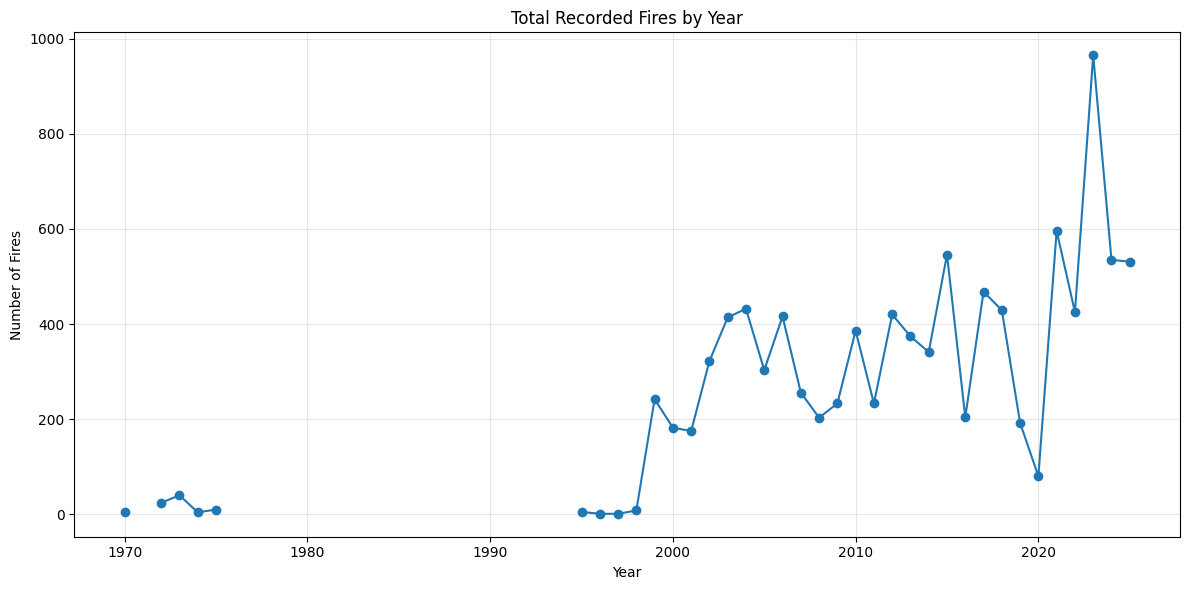

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_plot_pd["year"],
    annual_plot_pd["total_fires"],
    marker="o"
)

# Plot only years with actual records
plt.title("Total Recorded Fires by Year")
plt.xlabel("Year")
plt.ylabel("Number of Fires")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.14 Fires Greater Than 200 Hectares Over Time

This plot shows the annual number of fires classified as large fires
using the threshold `size_ha > 200`.

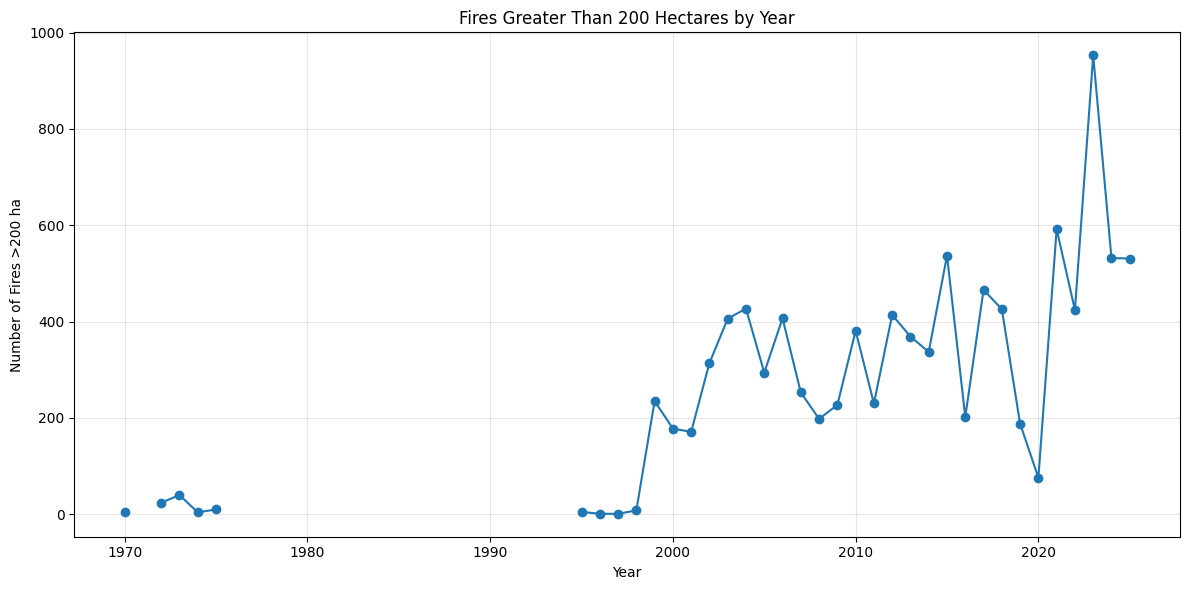

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_plot_pd["year"],
    annual_plot_pd["fires_gt_200ha"],
    marker="o"
)

plt.title("Fires Greater Than 200 Hectares by Year")
plt.xlabel("Year")
plt.ylabel("Number of Fires >200 ha")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.15 Proportion of Fires Greater Than 200 Hectares

The proportion is calculated as:

    Fires >200 ha / Total fires × 100

Years without records have NULL proportions and are therefore shown as
gaps rather than false zero values.

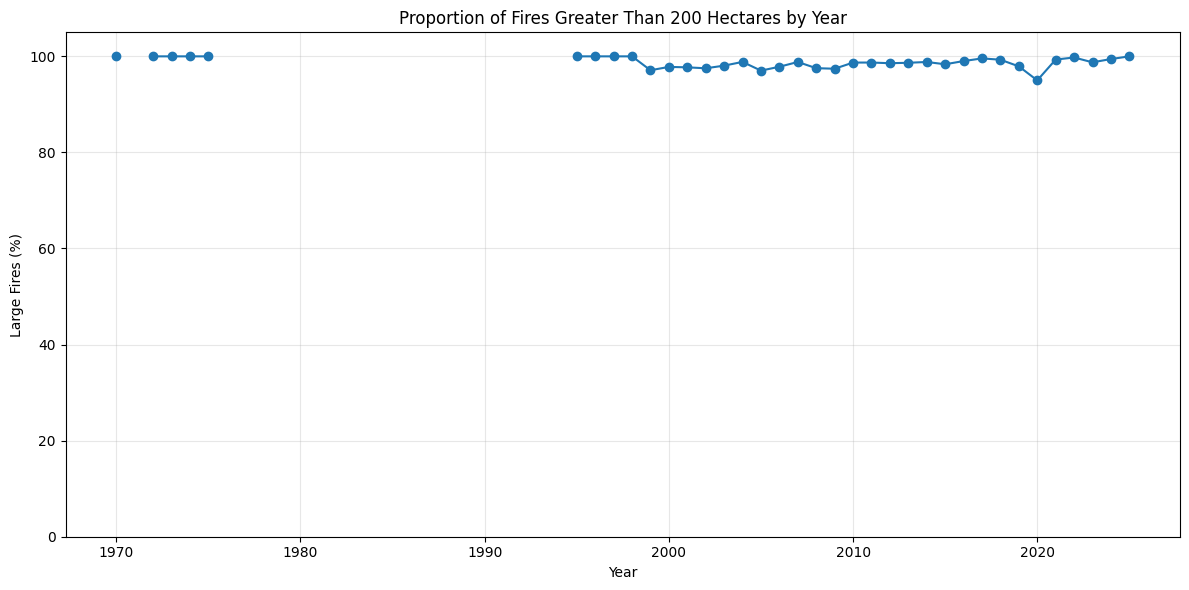

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_plot_pd["year"],
    annual_plot_pd["proportion_fires_gt_200_pct"],
    marker="o"
)

plt.title("Proportion of Fires Greater Than 200 Hectares by Year")
plt.xlabel("Year")
plt.ylabel("Large Fires (%)")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.16 Total Burned Area vs. Burned Area from Fires Greater Than 200 Hectares

Both series are overlaid on one chart. Because fires larger than 200 ha
account for almost all burned area, the two lines nearly coincide; the shaded
gap is the area contributed by fires of 200 ha or less.

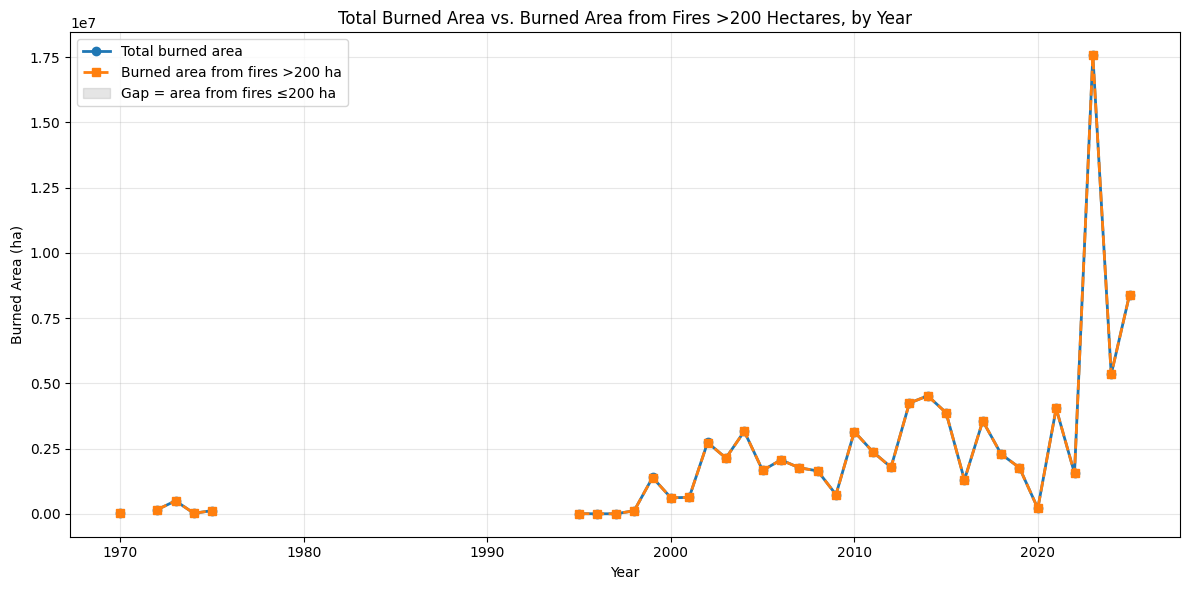

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_plot_pd["year"],
    annual_plot_pd["total_burned_area_ha"],
    marker="o", linewidth=2,
    label="Total burned area"
)
plt.plot(
    annual_plot_pd["year"],
    annual_plot_pd["burned_area_gt_200ha"],
    marker="s", linewidth=2, linestyle="--",
    label="Burned area from fires >200 ha"
)
plt.fill_between(
    annual_plot_pd["year"],
    annual_plot_pd["total_burned_area_ha"],
    annual_plot_pd["burned_area_gt_200ha"],
    alpha=0.2, color="gray",
    label="Gap = area from fires \u2264200 ha"
)

plt.title("Total Burned Area vs. Burned Area from Fires >200 Hectares, by Year")
plt.xlabel("Year")
plt.ylabel("Burned Area (ha)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.17 Proportion of Burned Area Attributable to Large Fires

The proportion is calculated as:

    Area from fires >200 ha / Total recorded area × 100

This measure directly evaluates the degree to which burned area is
concentrated in large fires.

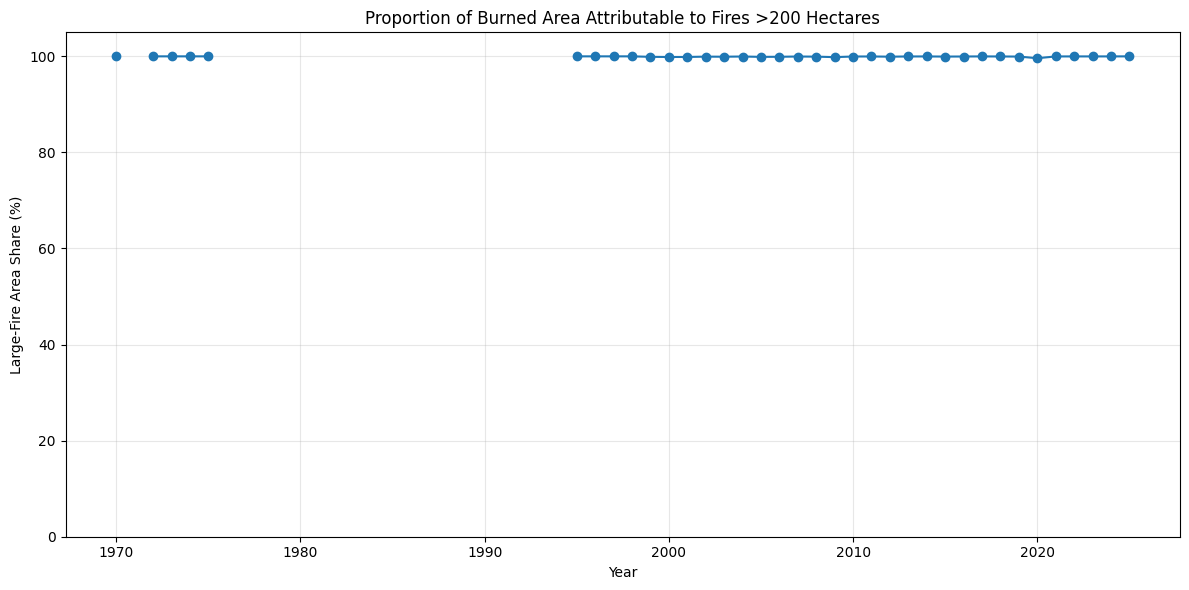

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_plot_pd["year"],
    annual_plot_pd["proportion_area_gt_200_pct"],
    marker="o"
)

plt.title(
    "Proportion of Burned Area Attributable to Fires >200 Hectares"
)
plt.xlabel("Year")
plt.ylabel("Large-Fire Area Share (%)")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.18 Total Recorded Fires Across Agencies

Only agencies represented in the 10,000-record extract are plotted.

Absence of an agency from the extract does not mean that the agency
experienced no fires.

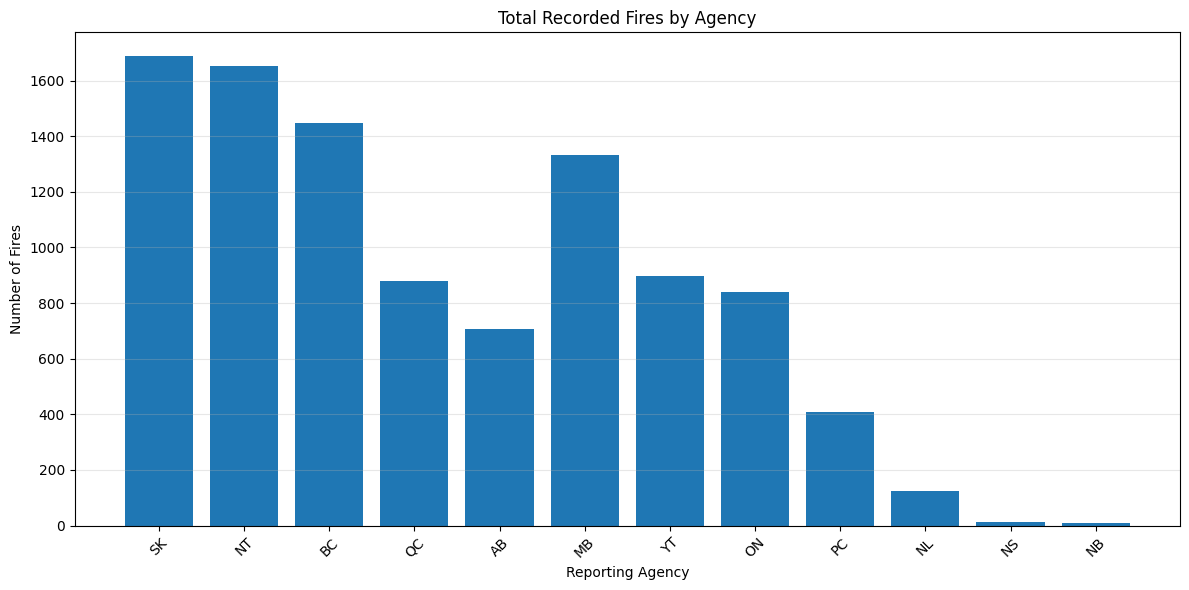

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    agency_plot_pd["src_agency"],
    agency_plot_pd["total_fires"]
)

plt.title("Total Recorded Fires by Agency")
plt.xlabel("Reporting Agency")
plt.ylabel("Number of Fires")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4.19 Fires Greater Than 200 Hectares by Agency

This visualization compares the number of large fires recorded by each
agency in the study extract.

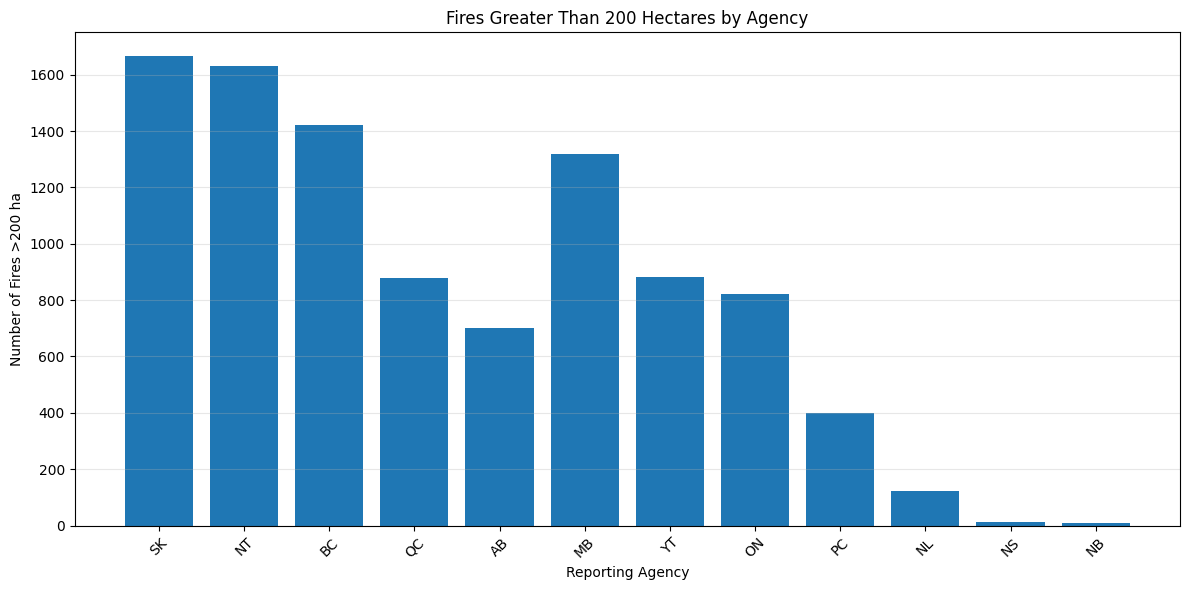

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    agency_plot_pd["src_agency"],
    agency_plot_pd["fires_gt_200ha"]
)

plt.title("Fires Greater Than 200 Hectares by Agency")
plt.xlabel("Reporting Agency")
plt.ylabel("Number of Fires >200 ha")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4.20 Proportion of Fires Greater Than 200 Hectares by Agency

The proportion measures the concentration of recorded fire events above
the 200-hectare threshold within each agency's records.

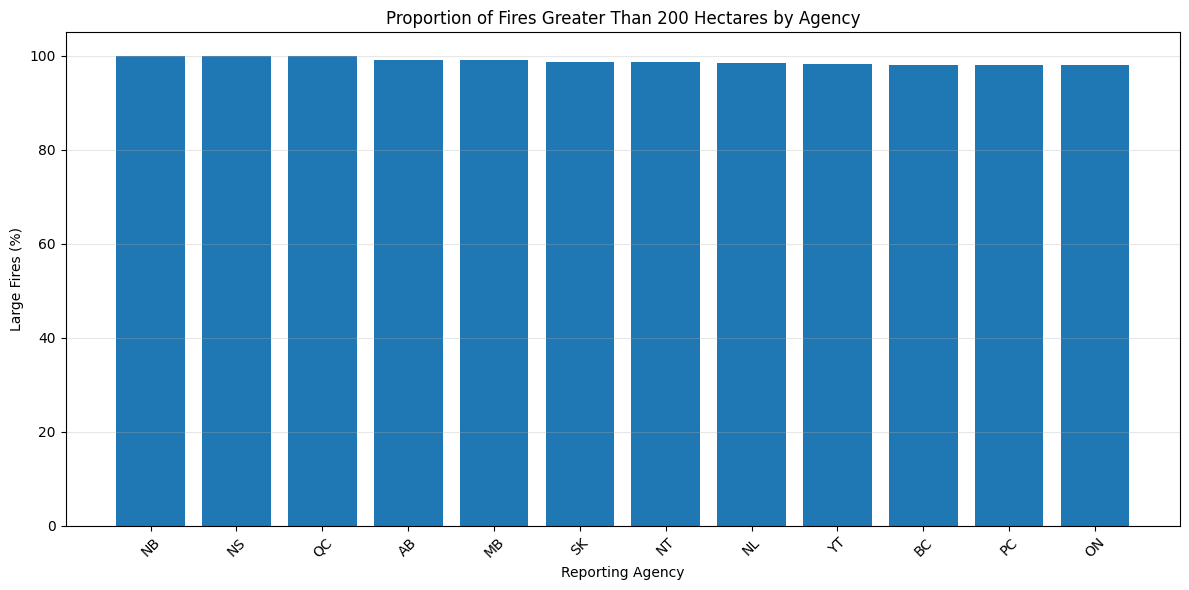

In [ ]:
agency_prop_pd = (
    agency_plot_pd
    .sort_values("proportion_fires_gt_200_pct", ascending=False)
)

plt.figure(figsize=(12, 6))

plt.bar(
    agency_prop_pd["src_agency"],
    agency_prop_pd["proportion_fires_gt_200_pct"]
)

plt.title("Proportion of Fires Greater Than 200 Hectares by Agency")
plt.xlabel("Reporting Agency")
plt.ylabel("Large Fires (%)")
plt.ylim(0, 105)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4.21 Burned Area by Agency: Total vs. Fires Greater Than 200 Hectares

Total burned area and burned area from fires greater than 200 ha are shown
side by side for each reporting agency.

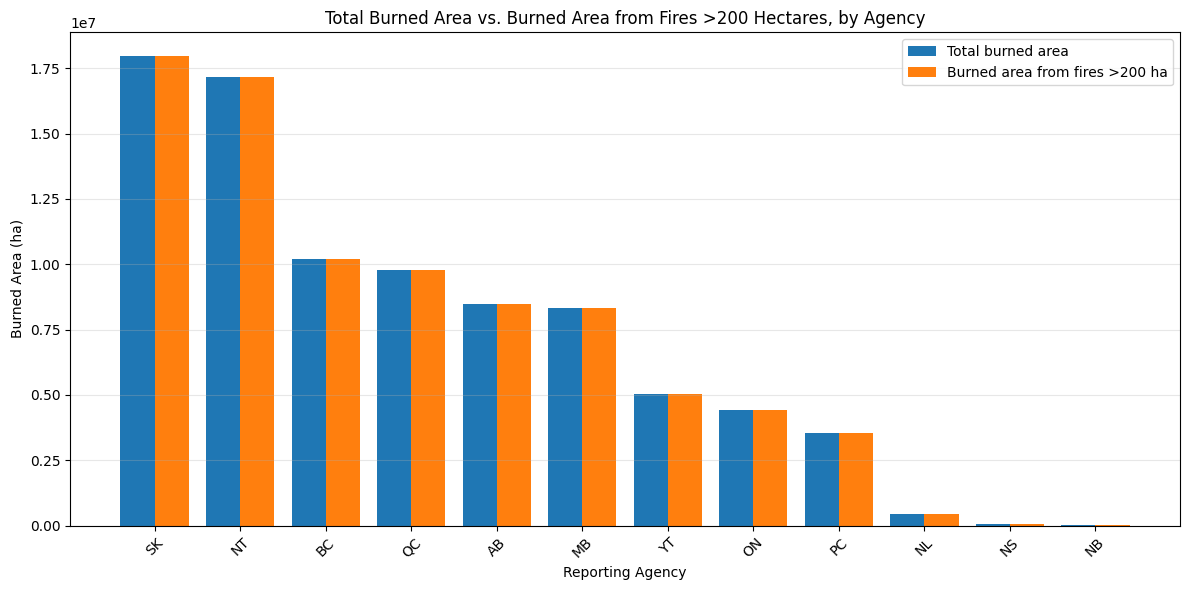

In [ ]:
import numpy as np

x = np.arange(len(agency_plot_pd))
bar_width = 0.4

plt.figure(figsize=(12, 6))

plt.bar(
    x - bar_width / 2,
    agency_plot_pd["total_burned_area_ha"],
    width=bar_width, label="Total burned area"
)
plt.bar(
    x + bar_width / 2,
    agency_plot_pd["burned_area_gt_200ha"],
    width=bar_width, label="Burned area from fires >200 ha"
)

plt.title("Total Burned Area vs. Burned Area from Fires >200 Hectares, by Agency")
plt.xlabel("Reporting Agency")
plt.ylabel("Burned Area (ha)")
plt.xticks(x, agency_plot_pd["src_agency"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4.22 Phase 4 Summary Table

The following table provides the six required large-fire concentration
measures in a compact form for reporting.

In [ ]:
phase4_summary = annual_complete.select(
    "year",
    "total_fires",
    "fires_gt_200ha",
    "proportion_fires_gt_200_pct",
    "total_burned_area_ha",
    "burned_area_gt_200ha",
    "proportion_area_gt_200_pct",
    "record_status"
)

phase4_summary.show(100, truncate=False)

+----+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+---------------------+
|year|total_fires|fires_gt_200ha|proportion_fires_gt_200_pct|total_burned_area_ha|burned_area_gt_200ha|proportion_area_gt_200_pct|record_status        |
+----+-----------+--------------+---------------------------+--------------------+--------------------+--------------------------+---------------------+
|1970|4          |4             |100.0                      |14784.9187          |14784.9187          |100.0                     |Records present      |
|1971|NULL       |NULL          |NULL                       |NULL                |NULL                |NULL                      |No records in extract|
|1972|24         |24            |100.0                      |158430.0            |158430.0            |100.0                     |Records present      |
|1973|40         |40            |100.0                      |496836.832          |

## 4.23 Phase 4 Validation

The following checks verify:

- all six required measures were generated;
- the number of records remains 10,000;
- large-fire counts do not exceed total fire counts;
- large-fire area does not exceed total recorded area; and
- proportions remain within the expected 0–100% range.

In [ ]:
# Record count
record_count = df_phase4.count()

# Invalid fire-count relationships
invalid_fire_counts = (
    annual_complete
    .filter(
        F.col("fires_gt_200ha") >
        F.col("total_fires")
    )
    .count()
)

# Invalid burned-area relationships
invalid_area_values = (
    annual_complete
    .filter(
        F.col("burned_area_gt_200ha") >
        F.col("total_burned_area_ha")
    )
    .count()
)

# Invalid proportions
invalid_fire_proportions = (
    annual_complete
    .filter(
        (F.col("proportion_fires_gt_200_pct") < 0) |
        (F.col("proportion_fires_gt_200_pct") > 100)
    )
    .count()
)

invalid_area_proportions = (
    annual_complete
    .filter(
        (F.col("proportion_area_gt_200_pct") < 0) |
        (F.col("proportion_area_gt_200_pct") > 100)
    )
    .count()
)

print("=" * 60)
print("PHASE 4 VALIDATION")
print("=" * 60)

print(
    "Record count:",
    record_count,
    "|",
    "PASS" if record_count == 10000 else "REVIEW"
)

print(
    "Large-fire count <= total-fire count:",
    "PASS" if invalid_fire_counts == 0 else "FAIL"
)

print(
    "Large-fire area <= total area:",
    "PASS" if invalid_area_values == 0 else "FAIL"
)

print(
    "Fire proportions within 0-100%:",
    "PASS" if invalid_fire_proportions == 0 else "FAIL"
)

print(
    "Area proportions within 0-100%:",
    "PASS" if invalid_area_proportions == 0 else "FAIL"
)

PHASE 4 VALIDATION
Record count: 10000 | PASS
Large-fire count <= total-fire count: PASS
Large-fire area <= total area: PASS
Fire proportions within 0-100%: PASS
Area proportions within 0-100%: PASS


## 4.24 Export Phase 4 Aggregated Results

The annual and agency-level results are exported for use in the final
report and subsequent phases of visualization and interpretation.

In [ ]:
# Annual results
final_annual_phase4.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("/content/phase4_annual_large_fire_concentration")

# Agency results
agency_concentration.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("/content/phase4_agency_large_fire_concentration")

## 4.25 Phase 4 Completion

Phase 4 is complete when the following have been successfully produced:

- annual large-fire concentration measures;
- agency-level large-fire concentration measures;
- explicit identification of years with no records;
- explicit handling of zero or missing denominators;
- comparison with official annual NFDB counts where available;
- annual time-series visualizations;
- agency-level visualizations; and
- validation showing that the calculated proportions and counts are
  internally consistent.

Missing years are not interpreted as zero wildfire activity. They are
classified as years with no records represented in the study extract.

Similarly, differences between the project extract and official NFDB
tables are treated as coverage differences unless the source definitions
demonstrate that the datasets should be identical.

In [ ]:
# Final automated completion check

required_annual_columns = [
    "year",
    "total_fires",
    "fires_gt_200ha",
    "proportion_fires_gt_200_pct",
    "total_burned_area_ha",
    "burned_area_gt_200ha",
    "proportion_area_gt_200_pct"
]

required_agency_columns = [
    "src_agency",
    "total_fires",
    "fires_gt_200ha",
    "proportion_fires_gt_200_pct",
    "total_burned_area_ha",
    "burned_area_gt_200ha",
    "proportion_area_gt_200_pct"
]

annual_check = all(
    col in final_annual_phase4.columns
    for col in required_annual_columns
)

agency_check = all(
    col in agency_concentration.columns
    for col in required_agency_columns
)

record_check = (df_phase4.count() == 10000)

validation_check = (
    invalid_fire_counts == 0 and
    invalid_area_values == 0 and
    invalid_fire_proportions == 0 and
    invalid_area_proportions == 0
)

print("=" * 60)
print("PHASE 4 FINAL STATUS")
print("=" * 60)

print(
    "Annual measures:",
    "PASS" if annual_check else "FAIL"
)

print(
    "Agency measures:",
    "PASS" if agency_check else "FAIL"
)

print(
    "Original 10,000 records preserved:",
    "PASS" if record_check else "FAIL"
)

print(
    "Calculation validation:",
    "PASS" if validation_check else "FAIL"
)

if all([
    annual_check,
    agency_check,
    record_check,
    validation_check
]):
    print("\nPHASE 4 STATUS: COMPLETE")
else:
    print("\nPHASE 4 STATUS: REQUIRES REVIEW")

PHASE 4 FINAL STATUS
Annual measures: PASS
Agency measures: PASS
Original 10,000 records preserved: PASS
Calculation validation: PASS

PHASE 4 STATUS: COMPLETE


# Phase 7: Geospatial Analysis and Visualization

This phase extends the PySpark aggregation results into geographic and
visual analyses.

GeoPandas is used to validate fire-point geometries and coordinate
reference systems. Folium is used to create an interactive map of valid
fire locations, with separate layers for all valid fires and fires larger
than 200 hectares.

Matplotlib is used to visualize:

- annual fire counts;
- annual burned area;
- annual large-fire proportions;
- cause-level comparisons;
- agency-level results;
- large-fire area shares; and
- NFDB/NBAC burned-area differences.

Records identified during Phase 2 as having spatial-quality problems are
retained in the main dataset but excluded from geographic visualization.

## 7.1 Import Required Libraries

The analysis combines distributed Spark processing with GeoPandas and
Folium for geospatial processing and visualization.

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster

from pyspark.sql import functions as F

## 7.2 Define NFDB Source Paths

The official NFDB point shapefile is used for geometry and CRS validation.

The project CSV remains the principal record-level dataset used for the
10,000-record analytical extract.

In [ ]:
import os
import glob
import zipfile
import urllib.request
from pathlib import Path

# Official Natural Resources Canada NFDB point shapefile
SHAPEFILE_URL = (
    "https://cwfis.cfs.nrcan.gc.ca/downloads/"
    "nfdb/fire_pnt/current_version/NFDB_point_shp.zip"
)

EXTRACT_DIR = "/content/NFDB_point_shp"
ZIP_PATH = "/content/NFDB_point_shp.zip"

# -------------------------------------------------------
# 1. Search the current notebook environment
# -------------------------------------------------------
existing_shapefiles = glob.glob(
    "/content/**/*.shp",
    recursive=True
)

# Prefer the NFDB point shapefile
nfdb_candidates = [
    path for path in existing_shapefiles
    if "nfdb_point" in os.path.basename(path).lower()
]

print("Existing shapefiles found:", len(existing_shapefiles))

# -------------------------------------------------------
# 2. Download and extract if the NFDB shapefile is missing
# -------------------------------------------------------
if nfdb_candidates:
    SHAPEFILE_PATH = nfdb_candidates[0]
    print("Using existing NFDB shapefile:", SHAPEFILE_PATH)

else:
    print("NFDB shapefile not found. Downloading official data...")

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    try:
        urllib.request.urlretrieve(
            SHAPEFILE_URL,
            ZIP_PATH
        )

        print("Download completed.")

        with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
            zip_ref.extractall(EXTRACT_DIR)

        print("Extraction completed.")

        extracted_shapefiles = glob.glob(
            os.path.join(EXTRACT_DIR, "**", "*.shp"),
            recursive=True
        )

        nfdb_candidates = [
            path for path in extracted_shapefiles
            if "nfdb_point" in os.path.basename(path).lower()
        ]

        if not nfdb_candidates:
            raise FileNotFoundError(
                "Download/extraction finished, but no NFDB point "
                "shapefile was found. Inspect the extracted directory."
            )

        SHAPEFILE_PATH = nfdb_candidates[0]

    except Exception as e:
        raise RuntimeError(
            "Could not obtain the NFDB shapefile. Check your internet "
            "connection and inspect the official download directory: "
            + SHAPEFILE_URL
        ) from e

print("\nFinal shapefile path:")
print(SHAPEFILE_PATH)

print("File exists:", os.path.isfile(SHAPEFILE_PATH))

Existing shapefiles found: 0
NFDB shapefile not found. Downloading official data...
Download completed.
Extraction completed.

Final shapefile path:
/content/NFDB_point_shp/NFDB_point_20260811.shp
File exists: True


In [ ]:
# ---------------------------------------------------------
# Project CSV
# ---------------------------------------------------------
CSV_PATH = "/content/NFDB_point.csv"

# ---------------------------------------------------------
# Official NFDB shapefile
# ---------------------------------------------------------
SHAPEFILE_CANDIDATES = glob.glob(
    "/content/NFDB_point_shp/*.shp"
)

if not SHAPEFILE_CANDIDATES:
    raise FileNotFoundError(
        "No NFDB shapefile was found in /content/NFDB_point_shp/"
    )

SHAPEFILE_PATH = SHAPEFILE_CANDIDATES[0]

print("CSV:", CSV_PATH)
print("Shapefile:", SHAPEFILE_PATH)

CSV: /content/NFDB_point.csv
Shapefile: /content/NFDB_point_shp/NFDB_point_20260811.shp


In [ ]:
import geopandas as gpd

# Load the official NFDB point shapefile
nfdb_gdf = gpd.read_file(SHAPEFILE_PATH)

print("Features:", len(nfdb_gdf))
print("Columns:", len(nfdb_gdf.columns))
print("CRS:", nfdb_gdf.crs)
print("EPSG:", nfdb_gdf.crs.to_epsg())

print("\nGeometry types:")
print(nfdb_gdf.geometry.geom_type.value_counts(dropna=False))

print("\nFirst five records:")
display(nfdb_gdf.head())

/usr/local/lib/python3.13/dist-packages/geopandas/io/file.py:582: UserWarning: Error parsing datetimes, original strings are returned: Out of bounds nanosecond timestamp: 1499-12-23, at position 18784. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Features: 448618
Columns: 25
CRS: EPSG:3978
EPSG: 3978

Geometry types:
Point    448618
Name: count, dtype: int64

First five records:


,NFDBFIREID,SRC_AGENCY,NAT_PARK,FIRE_ID,FIRENAME,LATITUDE,LONGITUDE,YEAR,MONTH,DAY,...,CAUSE2,FIRE_TYPE,RESPONSE,PROTZONE,PRESCRIBED,MORE_INFO,CFS_NOTE1,CFS_NOTE2,ACQ_DATE,geometry
0,AB-2024-CWF-001-2024,AB,None,CWF-001-2024,None,50.066333,-114.154883,2024,1,2,...,H,Wildfire,None,None,None,Calgary Forest Area,None,None,2025-04-07,POINT Z (-1345400.786 322485.621 0)
1,AB-2024-HWF-001-2024,AB,None,HWF-001-2024,None,57.912833,-116.334050,2024,1,5,...,H,Wildfire,None,None,None,High Level Forest Area,None,None,2025-04-07,POINT Z (-1210041.546 1182823.657 0)
2,AB-2024-SWF-001-2024,AB,None,SWF-001-2024,None,56.575550,-115.216533,2024,1,17,...,H,Wildfire,None,None,None,Slave Lake Forest Area,None,None,2025-04-07,POINT Z (-1194304.684 1023994.495 0)
3,AB-2024-LWF-001-2024,AB,None,LWF-001-2024,None,55.957361,-110.709667,2024,1,9,...,H,Wildfire,None,None,None,Lac La Biche Forest Area,None,None,2025-04-07,POINT Z (-950764.968 883261.867 0)
4,AB-2024-LWF-002-2024,AB,None,LWF-002-2024,None,55.957361,-110.709667,2024,1,9,...,H,Wildfire,None,None,None,Lac La Biche Forest Area,None,None,2025-04-07,POINT Z (-950764.968 883261.867 0)
